In [9]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import time

In [ ]:
# def tabprint(x):
#     return "\t".join(map(str, x))

# numb = "57"
# tumor = "t"+numb
# folder = "/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"

# #infilename = "/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".bin_count_table_good_cells.txt"
# #infilename = "/mnt/wigclust23/data/safe/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".bin_count_table_with_cluster.txt"
# infilename = "/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".bin_count_table_all_cells.txt"

# 
# #table = pd.read_csv(infilename, sep="\t")
# cells = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/"+tumor+".not_broken_final_list.txt", header = None)[0].values
# #cells = pd.read_csv(folder+"cleaned_cells_wigler.txt", header=None)[0].tolist()


In [12]:
infilename = "../data/t57.bin_count_table_all_cells.txt"
bincounts = pd.read_csv(infilename, sep = "\t")
cells = pd.read_csv("../data/t57.not_broken_final_list.txt", header=None)[0].values
break_points = pd.read_csv("../data/enca57_1M.hg19.5k.k50.varbin.short.cbs.txt", sep="\t")
normal_cells = pd.read_csv("../data/normal_cells.txt", header=None, sep="\t")[0].values

In [13]:
print(len(bincounts))
bincounts.head()

89


,chrom,loc.start,loc.end,abstart,abend,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,...,TTTTGGAGTTTGCGTCT,TTTTGGATTCCTAGAGA,TTTTGGGAACAATAAGC,TTTTGGGGGTTTTCAGA,TTTTGGGTCTTTAGTCG,TTTTGGGTCTTTCTACT,TTTTGGTAAGCTCAAGT,TTTTGGTGCAGGAATCA,TTTTGGTGCAGGAGAAG,TTTTGGTTTGGAAGTAC
0,chr1,0,45387037,0,45387037,570,1604,403,1325,853,...,214,1224,790,399,1536,1146,1064,961,16,834
1,chr1,45972336,119478274,45972336,119478274,928,5401,596,4437,2675,...,1421,2223,1209,593,4682,1092,671,3250,882,1429
2,chr1,120035598,175362842,120035598,175362842,506,2172,294,1671,1987,...,299,785,542,2015,1815,705,388,1264,2146,669
3,chr1,175900450,182029442,175900450,182029442,83,230,66,184,232,...,12,142,72,230,181,74,63,76,250,132
4,chr1,182578512,248389233,182578512,248389233,819,2760,612,1954,1335,...,152,1066,855,600,2012,1097,309,768,916,1228


In [14]:
table = bincounts[list(bincounts.columns[:5])+list(cells)]

In [ ]:
#break_points = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/enca"+numb+"_1M.hg19.5k.k50.varbin.short.cbs.txt", sep="\t")
break_points = break_points[break_points["chrom"]!="chrY"]

In [5]:
data = table[["chrom","abstart", "abend"]].copy()
for n in cells:
    data[n] = table[n].values

data["lengths"] = data["abend"]-data["abstart"]


In [6]:
data.head()


,chrom,abstart,abend,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,AAAACCAGTGAGTCTAC,AAAACCATGAGGAGAAG,...,TTTTGGACATGAAGTCG,TTTTGGAGTGAGAGTCG,TTTTGGATTCCTTCTCG,TTTTGGCTTGGCTCAAG,TTTTGGGAAATCCGTGA,TTTTGGGACCATGTACA,TTTTGGGACGAAGTAGC,TTTTGGGTGCAATGTCC,TTTTGGTATTCTAGTAC,lengths
0,chr1,0,45387037,570,1604,403,1325,853,310,866,...,1193,800,798,1995,971,1103,884,903,1125,45387037
1,chr1,45972336,119478274,928,5401,596,4437,2675,449,1412,...,4002,1326,2425,4022,1563,1792,2275,3026,3954,73505938
2,chr1,120035598,175362842,506,2172,294,1671,1987,253,769,...,3050,879,995,3032,789,896,1354,2382,1533,55327244
3,chr1,175900450,182029442,83,230,66,184,232,53,139,...,384,147,152,384,133,136,159,244,283,6128992
4,chr1,182578512,248389233,819,2760,612,1954,1335,462,1276,...,1963,1517,1092,2582,1421,1596,1217,1684,1892,65810721


In [7]:
def single_random_seed(q_table):
    s = []
        
    for j in range(len(q_table)):
        l2 = q_table.loc[j].values
        mi, mx = min(l2), max(l2)
        s.append([random() * (mx - mi) + mi, random() * (mx - mi) + mi])
    return s

In [8]:
def EM_algorithm(data,s, MIN_DIFF  = 0.001):
    
    obs_NV = np.array(data)[:,:].T
    log_likelihood = -np.Inf
    ## initialize log prob matrix, will be reused for speed.
    #logprob_NK = np.zeros(shape=(N,K))
    ## initialize multinomial emissions probabilities
    ## here, at random
    mult_KV = np.array(s).T
    mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]

    #print(mult_KV)
    for i in range(20):
        logmult_KV = np.log(mult_KV)
        #print(logmult_KV)
        #logmixprob_K = np.log(mixprob_K)
        ## multinomial probability is a dot product in log space
        ## that's cool.
        logprob_NK = np.dot(obs_NV, logmult_KV.T)
        #print(logprob_NK)
        logsum_N   = [logsumexp(list(x)) for x in logprob_NK]
        ## by the by, the total of the logsumN is ~ to the the log likelihood.
        ## in effect, what we are trying to maximize.
        logprob_NK = np.add(logprob_NK, -np.array(logsum_N)[:, np.newaxis])
        #print(logprob_NK)

        membership_NK = np.exp(logprob_NK)
        log_likelihood_last = log_likelihood
        log_likelihood = np.sum(logsum_N)

        mult_KV = np.dot(membership_NK.T, obs_NV)
        mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]
        #sum_K = np.sum(mult_KV, axis=1)
        #mult_KV = mult_KV / sum_K[:, np.newaxis]
        ## set a lowest possible multinomial value, and renorm
        #mult_KV = np.maximum(mult_KV, MINPROB)
        #sum_K   = np.sum(mult_KV, axis=1)
        log_diff = abs(log_likelihood-log_likelihood_last)
        #print (log_likelihood-log_likelihood_last )
        if log_diff < MIN_DIFF:
            #print ( 'enough already...' )
            break
    if log_diff > 10*MIN_DIFF:
        return logprob_NK, -np.Inf, mult_KV
    
    return logprob_NK, log_likelihood, mult_KV

In [9]:
def make_random_seeds(q_data, num_seeds=10):
    Seeds = []
    for i in range(num_seeds):
        s = []
        for j in range(len(q_data)):
            l2 = q_data.loc[j].values
            mi, mx = min(l2), max(l2)
            s.append([random() * (mx - mi) + mi, random() * (mx - mi) + mi])
        Seeds.append(s)
    return Seeds


In [10]:
def alg_on_single_seed(all_data):

    q_data = all_data/all_data.sum(axis=0)

    s = single_random_seed(q_data)
    print("single random seed done")
    
    logprob_NK, log_lik, mult_KV = EM_algorithm(all_data,s)
    
    return logprob_NK, log_lik, mult_KV

In [11]:
def alg_on_best_of_seeds(all_data, num_seeds=10):

    q_data = all_data/all_data.sum(axis=0)
    Seeds = make_random_seeds(q_data, num_seeds)

    # Compute EM for each seed, keep the the one with the highest log-likelihood
    best_log_lik = -np.Inf
    for s in Seeds:
        print("Trying new seed")
        logprob_NK, log_lik, mult_KV = EM_algorithm(all_data,s)
        if log_lik > best_log_lik:
            best_log_lik = log_lik
            best_logprob_NK = logprob_NK
            best_mult_KV = mult_KV
    
    return best_logprob_NK, best_log_lik, best_mult_KV
            
 

In [12]:
def ratio_of_ratios(all_data, threshold = 4/5, name=""):
    logprob_NK, log_lik, mult_KV = alg_on_best_of_seeds(all_data)
    cluster1 =  np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
    cluster2 =  np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
    cells_1 = [all_data.columns[i] for i in cluster1]
    cells_2 = [all_data.columns[i] for i in cluster2]
#     logmult_KV = np.log(mult_KV)
#     x , y  = logmult_KV[0], logmult_KV[1]

#     distances = np.abs(x - y) / np.sqrt(2)
#     sorted_indices = np.argsort(distances)[::-1]

#     top_n = 10
#     bottom_n = 30
#     top_indices = sorted_indices[:top_n]
#     bottom_indices = sorted_indices[-bottom_n:]
    
    counts_1 = all_data[cells_1].sum(axis = 1)
    counts_2 = all_data[cells_2].sum(axis = 1)
    
    total_1 = np.sum(counts_1)
    total_2 = np.sum(counts_2)

    chi2_values = []
    for i in range(len(counts_1)):
        observed = np.array([
            [counts_1[i], total_1 - counts_1[i]],
            [counts_2[i], total_2 - counts_2[i]]
        ])
        chi2, p, dof, expected = chi2_contingency(observed, correction=False)
        chi2_values.append(chi2)
    chi2_values = np.array(chi2_values)
    top_indices = np.argsort(chi2_values)[-10:][::-1]
    bottom_indices = np.argsort(chi2_values)[:30]
    
    ratios_1 = []
    ratios_2 = []
    for i in top_indices:
        r1 = []
        r2 = []
        for j in bottom_indices:
            if j!=i:
                r1.append(counts_1[i]/counts_1[j])
                r2.append(counts_2[i]/counts_2[j])
        ratios_1.append(r1)
        ratios_2.append(r2)
    slopes = []
    fig,ax = plt.subplots(1, figsize=(10, 10))
    
        
        
    for r1, r2 in zip(ratios_1, ratios_2): 
    #    fig,ax = plt.subplots(1, figsize=(10, 10))
        plt.scatter(r1, r2, alpha = 0.5)
    for r1, r2 in zip(ratios_1, ratios_2): 

        model = RANSACRegressor(LinearRegression(fit_intercept=False)).fit(np.array(r1).reshape(-1, 1), np.array(r2))
        slopes.append(model.estimator_.coef_[0])
        x_fit = np.linspace(min(r1), max(r1), 100).reshape(-1, 1)
        y_fit = model.predict(x_fit)
        plt.plot(x_fit, y_fit, linestyle='dashed')

    x = np.linspace(0, 10, 50)
    plt.plot(x, x, color='black')  # y=x line 

    y = threshold * x
    plt.plot(x, y, color='grey')  # y=(4/5)x line
    y = (1/threshold) * x
    plt.plot(x, y, color='grey')  # y=(5/4)x line

    # for p, q in fractions:
    #     slope = p / q
    #     y = slope * x
    #     if p == q:
    #         plt.plot(x, y, alpha = 0.2, color = "black")
    #     else:
    #         plt.plot(x, y, alpha = 0.2, color = "grey")
    l1 = str(len(cells_1))
    l2 = str(len(cells_2))
    plt.title(f"Ratio of Ratios Plot {name}1({l1}) and {name}2({l2})")
    plt.xlim([0,10])
    plt.ylim([0,10])
    return slopes, top_indices, bottom_indices, cells_1, cells_2, mult_KV

In [13]:
def recursive_em_split(data, cell_list, mult_KV_param=None, threshold=3/4, max_depth=10, current_depth=0, name="A"):
    """
    Recursively splits cell populations using EM algorithm until slopes are within threshold.
    
    Parameters:
    - data: the full genomic data
    - cell_list: list of cells in current population
    - mult_KV_param: multinomial parameters for current population (None for first call)
    - threshold: minimum slope threshold (splits rejected if slopes between threshold and 1/threshold)
    - max_depth: maximum recursion depth
    - current_depth: current recursion level
    - name: name/identifier for current population
    
    Returns:
    - Dictionary containing the tree structure with final populations and their mult_KV parameters
    """
    
    print(f"{'  ' * current_depth}Processing population {name} with {len(cell_list)} cells")
    
    # Set mult_KV_param if None
    if mult_KV_param is None:
        current_data = data[cell_list]
        q_data = current_data / current_data.sum(axis=0)
        mult_KV_param = q_data.mean(axis=1).values
    
    # Base cases
    threshold = min(threshold, 1/threshold)
    if current_depth >= max_depth:
        print(f"{'  ' * current_depth}Max depth reached for {name}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    if len(cell_list) < 50:  # Minimum population size
        print(f"{'  ' * current_depth}Population {name} too small to split")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    # Try to split the population
    try:
        current_data = data[cell_list]
        slopes, top_indices, bottom_indices, cells_1, cells_2, mult_KV = ratio_of_ratios(current_data, threshold, name)
        
        # Check if split should be rejected based on slope criteria
        max_slope = max(slopes)
        min_slope = min(slopes)
        
        print(f"{'  ' * current_depth}Slopes for {name}: max={max_slope:.3f}, min={min_slope:.3f}")
        
        # Reject split if slopes are between threshold and 1/threshold
        if threshold <= min_slope and max_slope <= 1/threshold:
            print(f"{'  ' * current_depth}Split rejected for {name}: slopes between {threshold:.3f} and {1/threshold:.3f}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        # Check if we have valid splits
        if len(cells_1) < 25 or len(cells_2) < 25:
            print(f"{'  ' * current_depth}Split produces too small subpopulations for {name}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        print(f"{'  ' * current_depth}Split accepted for {name}: {len(cells_1)} + {len(cells_2)} cells")
        
        # Recursively split both subpopulations
        result = {}
        
        # Split first subpopulation (pass mult_KV[0])
        sub_result_1 = recursive_em_split(
            data, cells_1, mult_KV[0], threshold, max_depth, current_depth + 1, name + "1"
        )
        result.update(sub_result_1)
        
        # Split second subpopulation (pass mult_KV[1])
        sub_result_2 = recursive_em_split(
            data, cells_2, mult_KV[1], threshold, max_depth, current_depth + 1, name + "2"
        )
        result.update(sub_result_2)
        
        return result
        
    except Exception as e:
        print(f"{'  ' * current_depth}Error splitting {name}: {e}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}

In [14]:
all_data = data[cells].copy()
q_data = all_data/all_data.sum(axis=0)

In [15]:
all_data.head()

,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,AAAACCAGTGAGTCTAC,AAAACCATGAGGAGAAG,AAAACCGAAATCGGTAT,AAAACCGAACCCGTACA,AAAACCGGACGTATTAA,...,TTTTGGAAGCGTAGACT,TTTTGGACATGAAGTCG,TTTTGGAGTGAGAGTCG,TTTTGGATTCCTTCTCG,TTTTGGCTTGGCTCAAG,TTTTGGGAAATCCGTGA,TTTTGGGACCATGTACA,TTTTGGGACGAAGTAGC,TTTTGGGTGCAATGTCC,TTTTGGTATTCTAGTAC
0,570,1604,403,1325,853,310,866,479,1113,1009,...,1160,1193,800,798,1995,971,1103,884,903,1125
1,928,5401,596,4437,2675,449,1412,1646,1941,3164,...,2108,4002,1326,2425,4022,1563,1792,2275,3026,3954
2,506,2172,294,1671,1987,253,769,649,974,1250,...,1030,3050,879,995,3032,789,896,1354,2382,1533
3,83,230,66,184,232,53,139,59,162,200,...,153,384,147,152,384,133,136,159,244,283
4,819,2760,612,1954,1335,462,1276,696,1681,1404,...,1759,1963,1517,1092,2582,1421,1596,1217,1684,1892


In [16]:
logprob_NK, log_lik, mult_KV = alg_on_single_seed(all_data)

single random seed done


In [17]:
cluster1 =  np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
cluster2 =  np.where(np.array([x-y for x,y in logprob_NK])<0)[0]

In [18]:
cells_1 = [all_data.columns[i] for i in cluster1]
cells_2 = [all_data.columns[i] for i in cluster2]

(array([ 2.,  0.,  1.,  1.,  0.,  0.,  2.,  1.,  1.,  4.,  4., 15., 54.,
         3.,  0.,  0.,  0.,  0.,  0.,  1.]),
 array([0.09282577, 0.16687183, 0.24091789, 0.31496395, 0.38901   ,
        0.46305606, 0.53710212, 0.61114818, 0.68519424, 0.7592403 ,
        0.83328636, 0.90733241, 0.98137847, 1.05542453, 1.12947059,
        1.20351665, 1.27756271, 1.35160876, 1.42565482, 1.49970088,
        1.57374694]),
 <BarContainer object of 20 artists>)

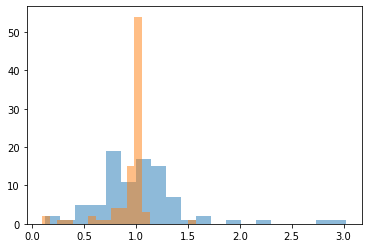

In [19]:
unif_1 = all_data[cells_1].sum(axis = 1)/data["lengths"]
unif_2 = all_data[cells_2].sum(axis = 1)/data["lengths"]
unif_1 = unif_1/np.median(unif_1)
unif_2 = unif_2/np.median(unif_2)
plt.hist(unif_1, bins = 20, alpha = 0.5)
plt.hist(unif_2, bins = 20, alpha = 0.5)

In [20]:
logmult_KV = np.log(mult_KV)
x , y  = logmult_KV[0], logmult_KV[1]

distances = np.abs(x - y) / np.sqrt(2)
sorted_indices = np.argsort(distances)[::-1]

top_n = 10
bottom_n = 30
top_indices = sorted_indices[:top_n]
bottom_indices = sorted_indices[-bottom_n:]

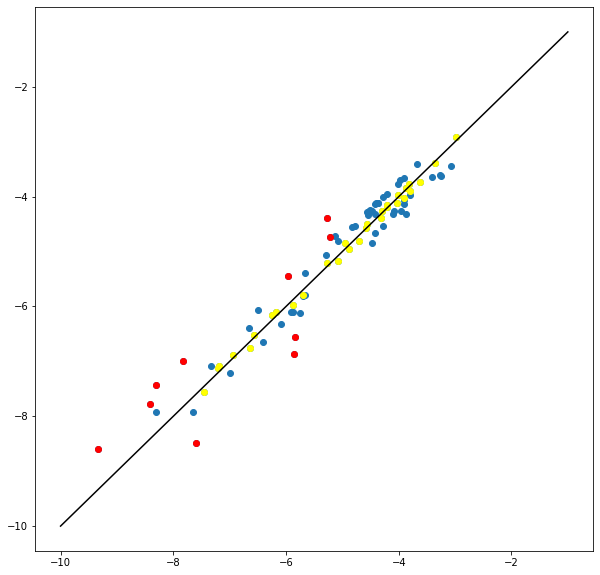

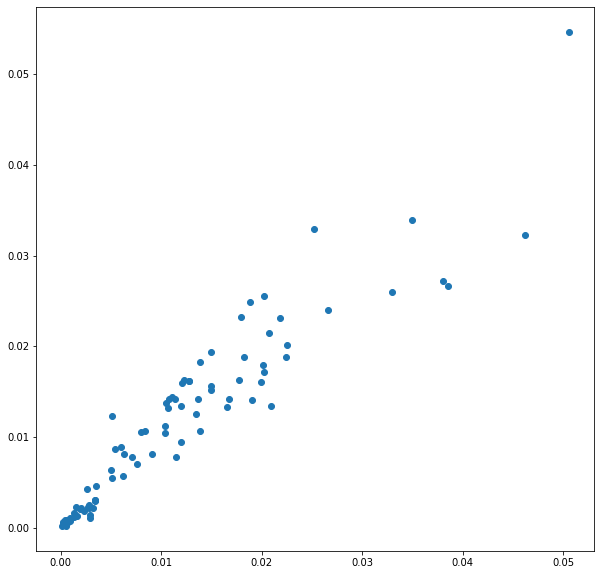

In [21]:
fig,ax = plt.subplots(1, figsize=(10, 10))
plt.scatter(logmult_KV[0], logmult_KV[1])
plt.scatter(x[top_indices], y[top_indices], color='red', label='Most different')
plt.scatter(x[bottom_indices], y[bottom_indices], color='yellow', label='Most alike')

plt.plot(range(-10,0), range(-10,0), color = "black", )
fig,ax = plt.subplots(1, figsize=(10, 10))
plt.scatter(mult_KV[0], mult_KV[1])

In [22]:
counts_1 = all_data[cells_1].sum(axis = 1)
counts_2 = all_data[cells_2].sum(axis = 1)

In [23]:
ratios_1 = []
ratios_2 = []
for i in top_indices:
    for j in bottom_indices:
        print(i,j)
        
        ratios_1.append(counts_1[i]/counts_1[j])
        ratios_2.append(counts_2[i]/counts_2[j])

56 70
56 35
56 18
56 41
56 7
56 17
56 19
56 69
56 15
56 80
56 16
56 32
56 64
56 66
56 12
56 74
56 65
56 85
56 30
56 76
56 61
56 88
56 48
56 36
56 5
56 81
56 33
56 57
56 23
56 26
54 70
54 35
54 18
54 41
54 7
54 17
54 19
54 69
54 15
54 80
54 16
54 32
54 64
54 66
54 12
54 74
54 65
54 85
54 30
54 76
54 61
54 88
54 48
54 36
54 5
54 81
54 33
54 57
54 23
54 26
21 70
21 35
21 18
21 41
21 7
21 17
21 19
21 69
21 15
21 80
21 16
21 32
21 64
21 66
21 12
21 74
21 65
21 85
21 30
21 76
21 61
21 88
21 48
21 36
21 5
21 81
21 33
21 57
21 23
21 26
52 70
52 35
52 18
52 41
52 7
52 17
52 19
52 69
52 15
52 80
52 16
52 32
52 64
52 66
52 12
52 74
52 65
52 85
52 30
52 76
52 61
52 88
52 48
52 36
52 5
52 81
52 33
52 57
52 23
52 26
9 70
9 35
9 18
9 41
9 7
9 17
9 19
9 69
9 15
9 80
9 16
9 32
9 64
9 66
9 12
9 74
9 65
9 85
9 30
9 76
9 61
9 88
9 48
9 36
9 5
9 81
9 33
9 57
9 23
9 26
45 70
45 35
45 18
45 41
45 7
45 17
45 19
45 69
45 15
45 80
45 16
45 32
45 64
45 66
45 12
45 74
45 65
45 85
45 30
45 76
45 61
45 88
45 48
45 

(0.0, 2.0)

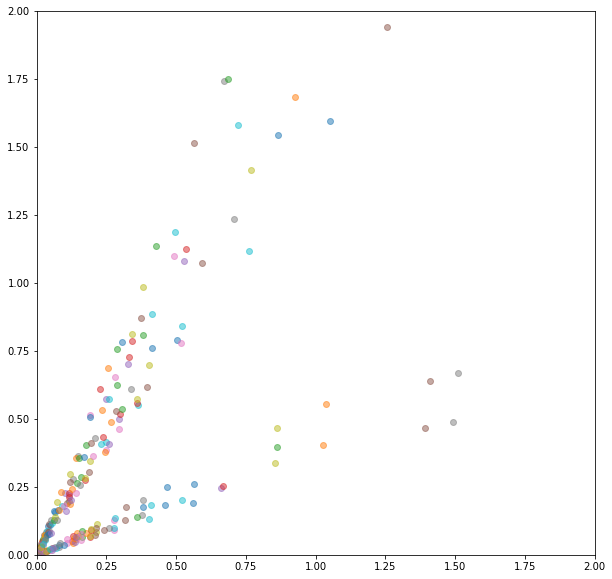

In [24]:
fig,ax = plt.subplots(1, figsize=(10, 10))
for r1, r2 in zip(ratios_1, ratios_2): 
#    fig,ax = plt.subplots(1, figsize=(10, 10))
    plt.scatter(r1, r2, alpha = 0.5)
plt.xlim([0,2])
plt.ylim([0,2])


Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


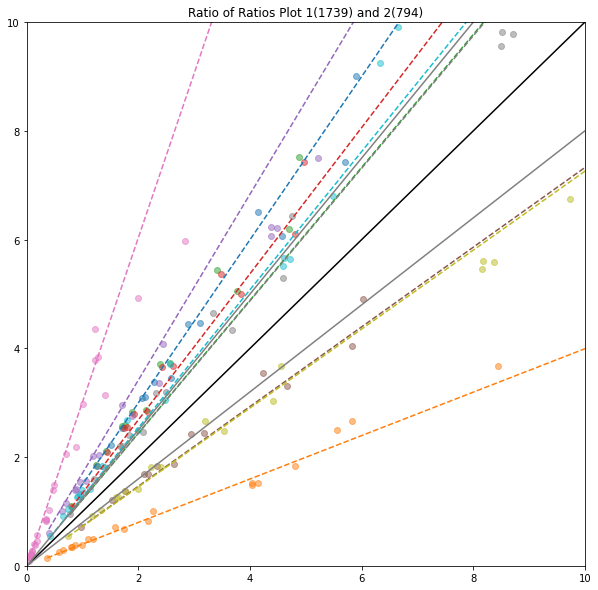

In [25]:

slopes, top_indices, bottom_indices, cells_1, cells_2, mult_KV = ratio_of_ratios(all_data)

(array([ 2.,  1.,  5.,  5., 19., 11., 17., 15.,  7.,  1.,  2.,  0.,  1.,
         0.,  1.,  0.,  0.,  0.,  1.,  1.]),
 array([0.12412223, 0.26926174, 0.41440125, 0.55954076, 0.70468027,
        0.84981978, 0.99495929, 1.1400988 , 1.28523831, 1.43037782,
        1.57551733, 1.72065684, 1.86579635, 2.01093586, 2.15607537,
        2.30121488, 2.44635439, 2.5914939 , 2.73663341, 2.88177292,
        3.02691243]),
 <BarContainer object of 20 artists>)

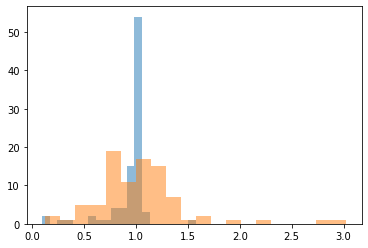

In [26]:
unif_1 = all_data[cells_1].sum(axis = 1)/data["lengths"]
unif_2 = all_data[cells_2].sum(axis = 1)/data["lengths"]
unif_1 = unif_1/np.median(unif_1)
unif_2 = unif_2/np.median(unif_2)
plt.hist(unif_1, bins = 20, alpha = 0.5)
plt.hist(unif_2, bins = 20, alpha = 0.5)

In [27]:
new_data1 = all_data[cells_1]
new_data2 = all_data[cells_2]

Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


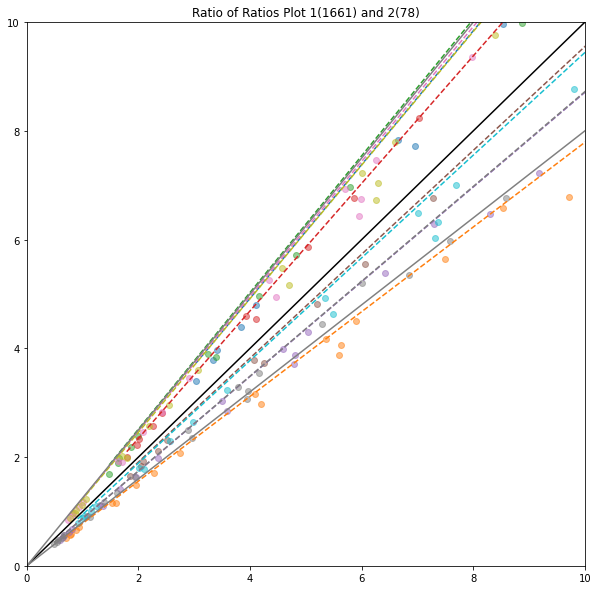

In [28]:
slopes1, top_indices1, bottom_indices1, cells_11, cells_12, mult_KV = ratio_of_ratios(new_data1)

(array([ 2.,  0.,  1.,  1.,  0.,  0.,  0.,  2.,  4.,  4., 11., 18., 23.,
        13.,  5.,  2.,  0.,  1.,  1.,  1.]),
 array([0.10025267, 0.17465425, 0.24905583, 0.32345741, 0.39785899,
        0.47226058, 0.54666216, 0.62106374, 0.69546532, 0.7698669 ,
        0.84426848, 0.91867007, 0.99307165, 1.06747323, 1.14187481,
        1.21627639, 1.29067798, 1.36507956, 1.43948114, 1.51388272,
        1.5882843 ]),
 <BarContainer object of 20 artists>)

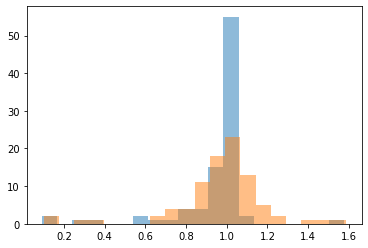

In [29]:
unif_1 = all_data[cells_11].sum(axis = 1)/data["lengths"]
unif_2 = all_data[cells_12].sum(axis = 1)/data["lengths"]
unif_1 = unif_1/np.median(unif_1)
unif_2 = unif_2/np.median(unif_2)
plt.hist(unif_1, bins = 20, alpha = 0.5)
plt.hist(unif_2, bins = 20, alpha = 0.5)

In [30]:
sorted((max(slopes1), min(slopes1), 4/5, 5/4))

[0.7790036896514654, 0.8, 1.25, 1.2569772179835934]

Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


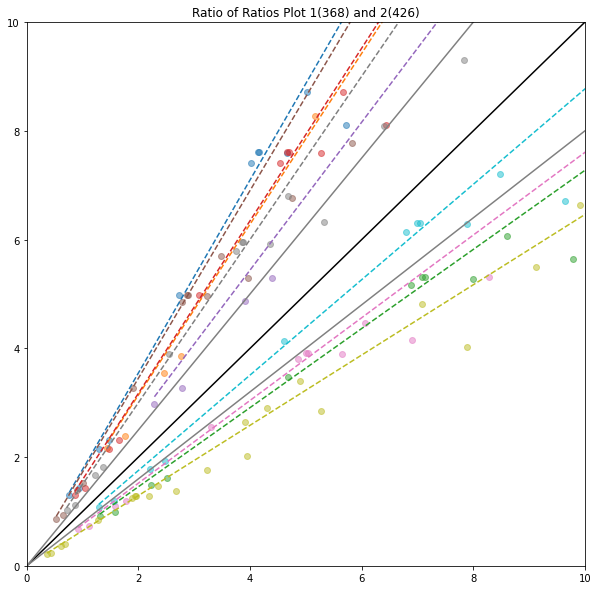

In [31]:
slopes2, top_indices2, bottom_indices2, cells_21, cells_22, mult_KV = ratio_of_ratios(new_data2)

(array([ 2.,  1.,  6.,  4., 22.,  6., 11., 16.,  9.,  7.,  1.,  0.,  1.,
         1.,  0.,  0.,  0.,  1.,  0.,  1.]),
 array([0.11049222, 0.24507888, 0.37966553, 0.51425218, 0.64883884,
        0.78342549, 0.91801214, 1.05259879, 1.18718545, 1.3217721 ,
        1.45635875, 1.59094541, 1.72553206, 1.86011871, 1.99470537,
        2.12929202, 2.26387867, 2.39846533, 2.53305198, 2.66763863,
        2.80222529]),
 <BarContainer object of 20 artists>)

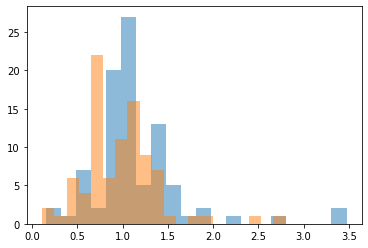

In [32]:
unif_1 = all_data[cells_21].sum(axis = 1)/data["lengths"]
unif_2 = all_data[cells_22].sum(axis = 1)/data["lengths"]
unif_1 = unif_1/np.median(unif_1)
unif_2 = unif_2/np.median(unif_2)
plt.hist(unif_1, bins = 20, alpha = 0.5)
plt.hist(unif_2, bins = 20, alpha = 0.5)

In [33]:
sorted((max(slopes2), min(slopes2), 0.7, 1/0.7))

[0.6461387684214958, 0.7, 1.4285714285714286, 1.7743024790262607]

In [34]:
# def recursive_em_split(data, cell_list, threshold=3/4, max_depth=10, current_depth=0, name="A"):
#     """
#     Recursively splits cell populations using EM algorithm until slopes are within threshold.
    
#     Parameters:
#     - data: the full genomic data
#     - cell_list: list of cells in current population
#     - threshold: minimum slope threshold (splits rejected if slopes between threshold and 1/threshold)
#     - max_depth: maximum recursion depth
#     - current_depth: current recursion level
#     - name: name/identifier for current population
    
#     Returns:
#     - Dictionary containing the tree structure with final populations
#     """
    
#     print(f"{'  ' * current_depth}Processing population {name} with {len(cell_list)} cells")
    
#     # Base cases
#     threshold = min(threshold, 1/threshold)
#     if current_depth >= max_depth:
#         print(f"{'  ' * current_depth}Max depth reached for {name}")
#         return {name: cell_list}
    
#     if len(cell_list) < 50:  # Minimum population size
#         print(f"{'  ' * current_depth}Population {name} too small to split")
#         return {name: cell_list}
    
#     # Try to split the population
#     try:
#         current_data = data[cell_list]
#         slopes, top_indices, bottom_indices, cells_1, cells_2, mult_KV = ratio_of_ratios(current_data, threshold, name)
#         # Check if split should be rejected based on slope criteria
#         max_slope = max(slopes)
#         min_slope = min(slopes)
        
#         print(f"{'  ' * current_depth}Slopes for {name}: max={max_slope:.3f}, min={min_slope:.3f}")
        
#         # Reject split if slopes are between threshold and 1/threshold
#         if threshold <= min_slope and max_slope <= 1/threshold:
#             print(f"{'  ' * current_depth}Split rejected for {name}: slopes between {threshold:.3f} and {1/threshold:.3f}")
#             return {name: cell_list}
        
#         # Check if we have valid splits
#         if len(cells_1) < 25 or len(cells_2) < 25:
#             print(f"{'  ' * current_depth}Split produces too small subpopulations for {name}")
#             return {name: cell_list}
        
#         print(f"{'  ' * current_depth}Split accepted for {name}: {len(cells_1)} + {len(cells_2)} cells")
        
#         # Recursively split both subpopulations
#         result = {}
        
#         # Split first subpopulation
#         sub_result_1 = recursive_em_split(
#             data, cells_1, threshold, max_depth, current_depth + 1, name + "1"
#         )
#         result.update(sub_result_1)
        
#         # Split second subpopulation  
#         sub_result_2 = recursive_em_split(
#             data, cells_2, threshold, max_depth, current_depth + 1, name + "2"
#         )
#         result.update(sub_result_2)
        
#         return result
        
#     except Exception as e:
#         print(f"{'  ' * current_depth}Error splitting {name}: {e}")
#         return {name: cell_list}


In [35]:
q_data = all_data/all_data.sum(axis=0)
mult_KV_param = q_data.mean(axis=1).values

Processing population A with 2533 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Slopes for A: max=2.187, min=0.372
Split accepted for A: 790 + 1743 cells
  Processing population A1 with 790 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
  Slopes for A1: max=1.778, min=0.641
  Split accepted for A1: 365 + 425 cells
    Processing population A11 with 365 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
    Slopes for A11: max=1.156, min=0.724
    Split accepted for A11: 145 + 220 cells
      Processing population A111 with 145 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new 

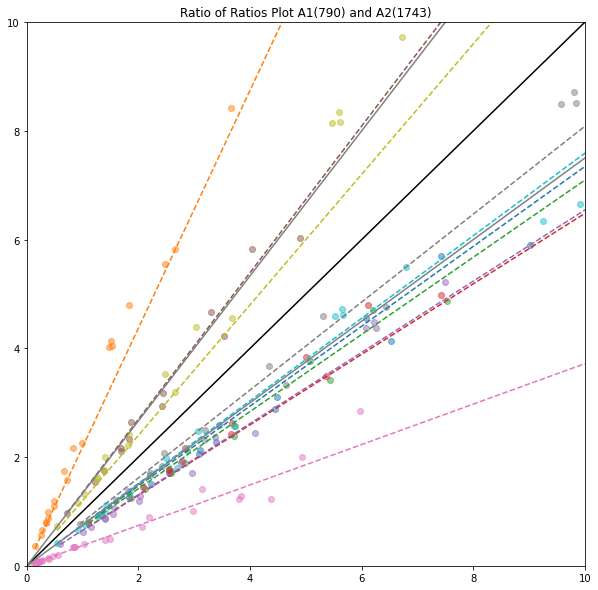

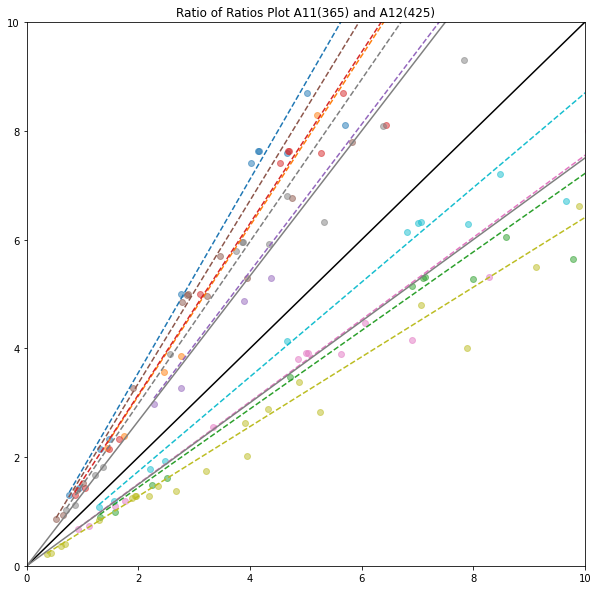

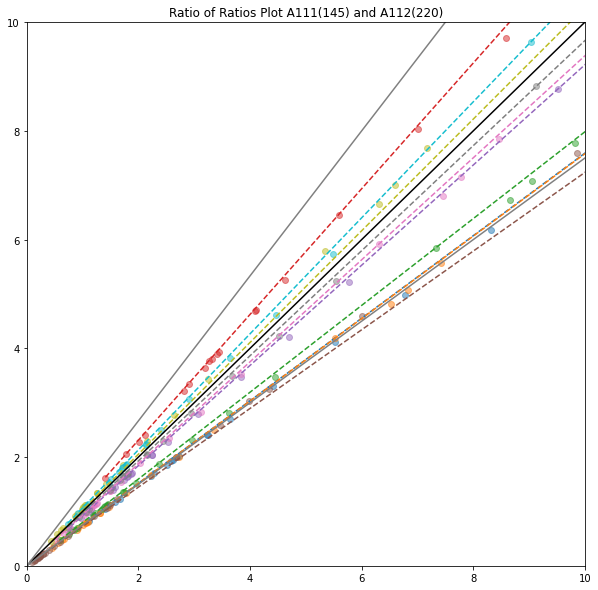

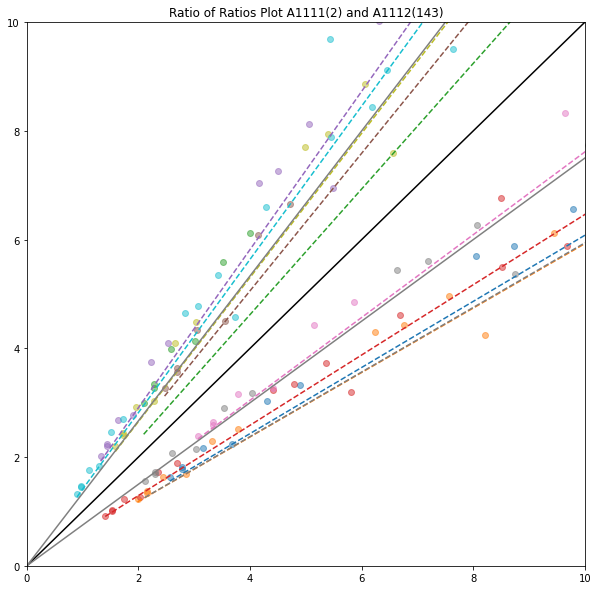

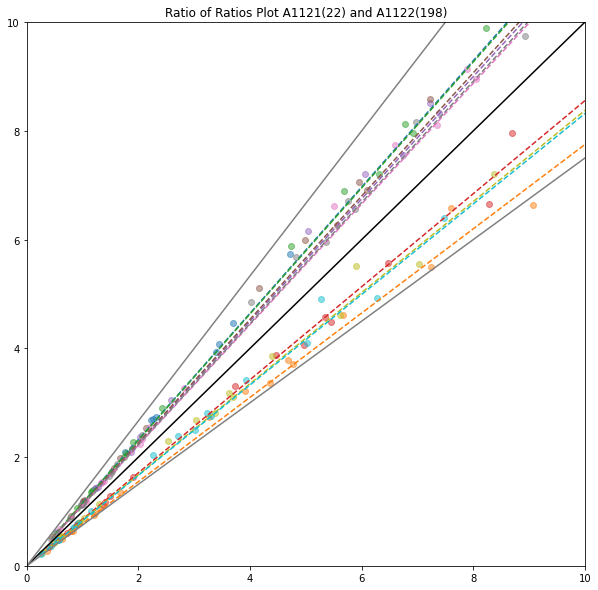

...

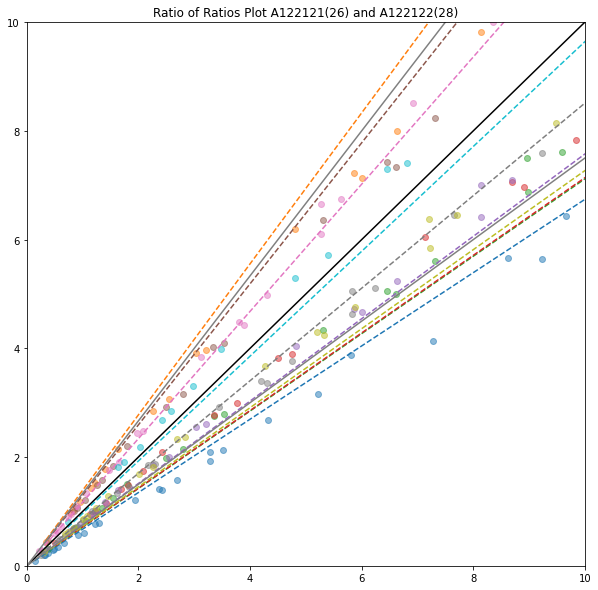

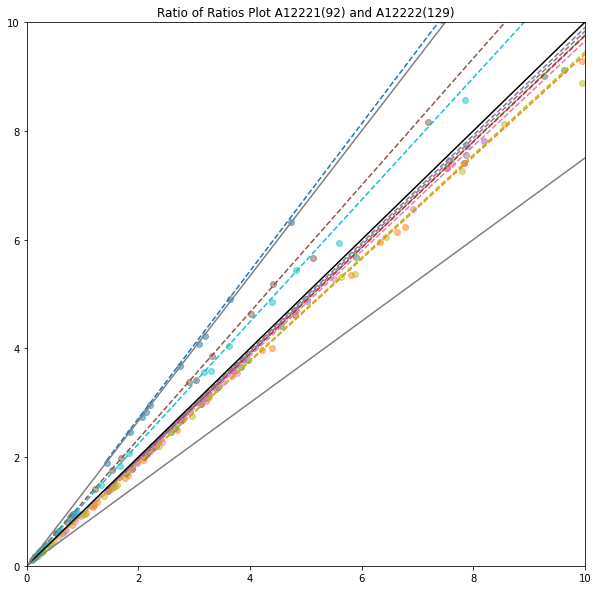

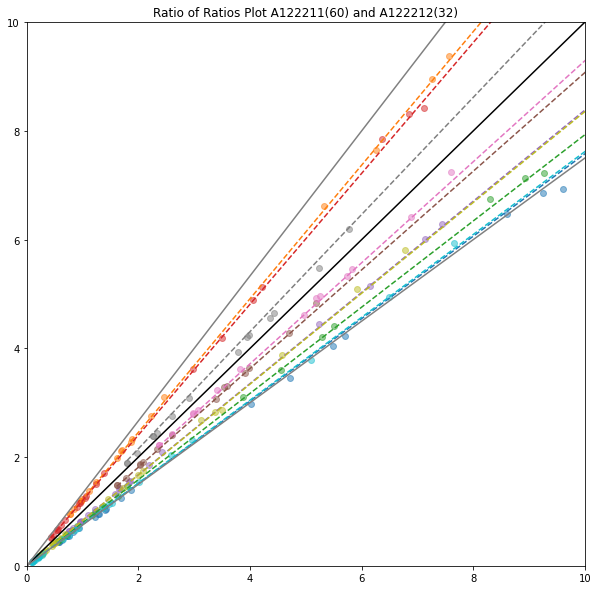

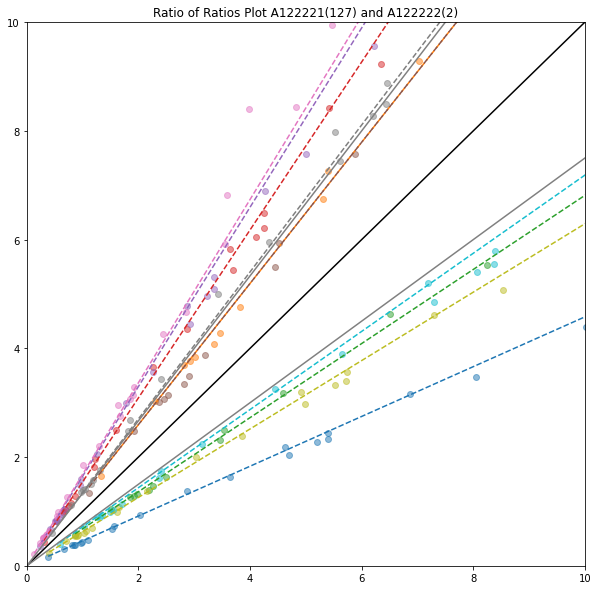

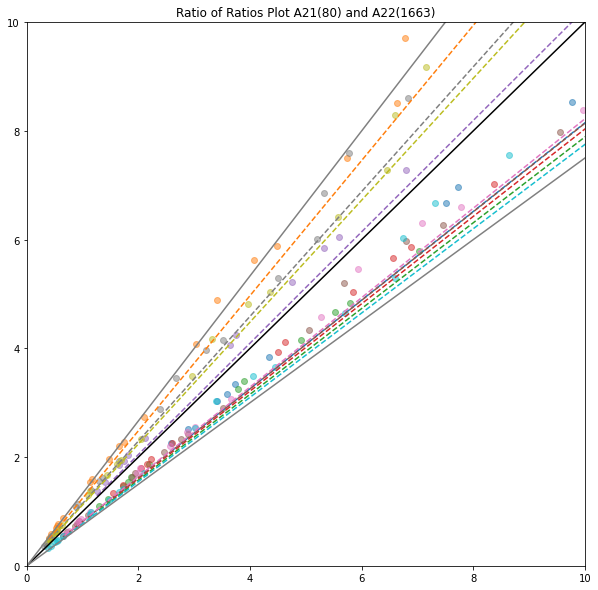

In [36]:
final_populations = recursive_em_split(all_data, cells,threshold=3/4, max_depth=10, current_depth=0, name="A")

In [37]:
len(final_populations)

9

In [38]:
print(final_populations.keys())

dict_keys(['A111', 'A112', 'A121', 'A12211', 'A122121', 'A122122', 'A12221', 'A12222', 'A2'])


In [39]:
for A in final_populations:
    print(A, len(final_populations[A]["cells"]))

A111 145
A112 220
A121 95
A12211 55
A122121 26
A122122 28
A12221 92
A12222 129
A2 1743


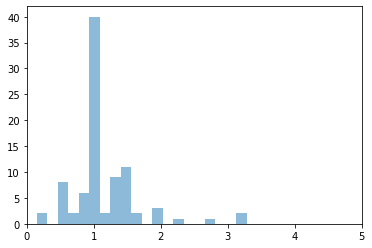

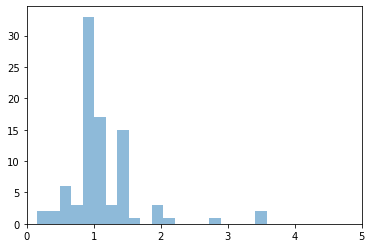

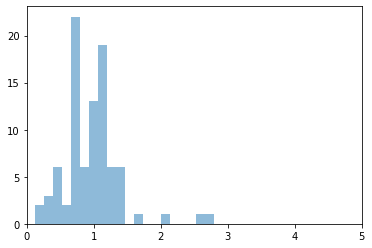

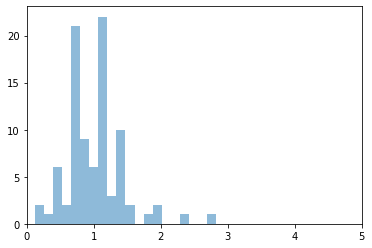

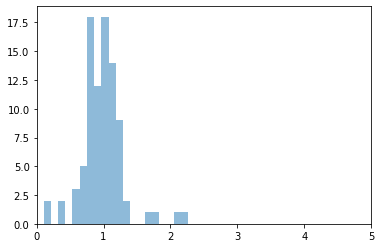

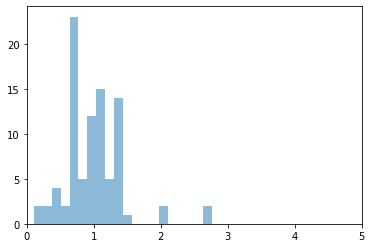

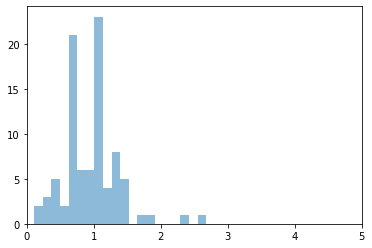

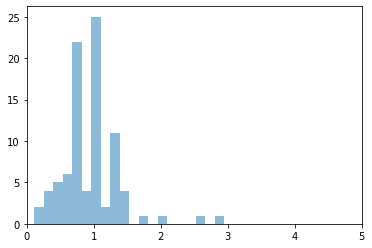

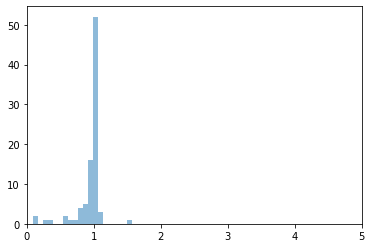

In [40]:
#Check for uniformity accross segments in each population
dev_from_median = {}
unif_dict = {}
for pop in final_populations:
    pop_cells = final_populations[pop]["cells"]
    pop_data = all_data[pop_cells]
    unif = pop_data.sum(axis = 1)/data["lengths"]
    unif = unif/np.median(unif)
    plt.hist(unif, bins = 20, alpha = 0.5, label = pop)
    plt.xlim([0,5])
    dev_from_median[pop] = np.median(np.abs(unif - 1))
    #plt.title(f"Population {pop} with {len(pop_cells)} cells")
    plt.show()

In [ ]:
#normal_cells = pd.read_csv("/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/"+tumor+"/normal_cells.txt", header = None,sep = "\t")[0].values



In [42]:
# Population with least deviation from median is likely normal
# Let us pick this population as normal
min_dev_pop = min(dev_from_median, key=dev_from_median.get)

In [43]:
# Check overlap with known normal cells
print(len([c for c in final_populations[min_dev_pop]["cells"] if c in normal_cells]))
len(final_populations[min_dev_pop]["cells"]), len(normal_cells)

1623


(1743, 1623)

Processing population B with 2533 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Slopes for B: max=2.900, min=0.435
Split accepted for B: 1739 + 794 cells
  Processing population B1 with 1739 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
  Slopes for B1: max=1.221, min=0.765
  Split rejected for B1: slopes between 0.750 and 1.333
  Processing population B2 with 794 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
  Slopes for B2: max=1.544, min=0.558
  Split accepted for B2: 426 + 368 cells
    Processing population B21 with 426 cells
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying 

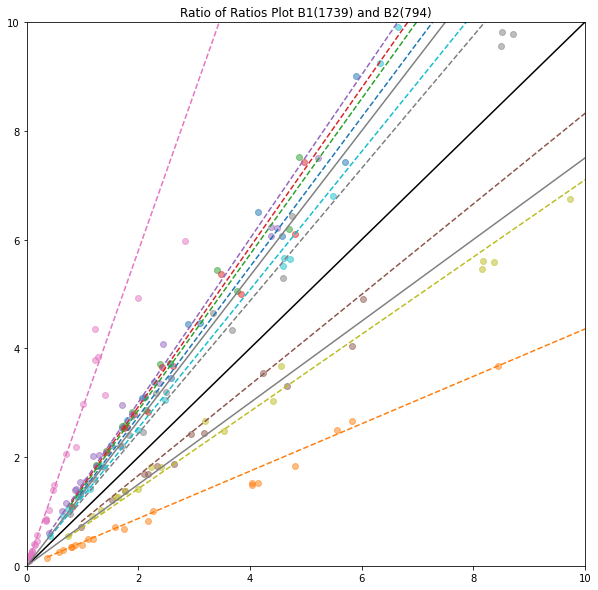

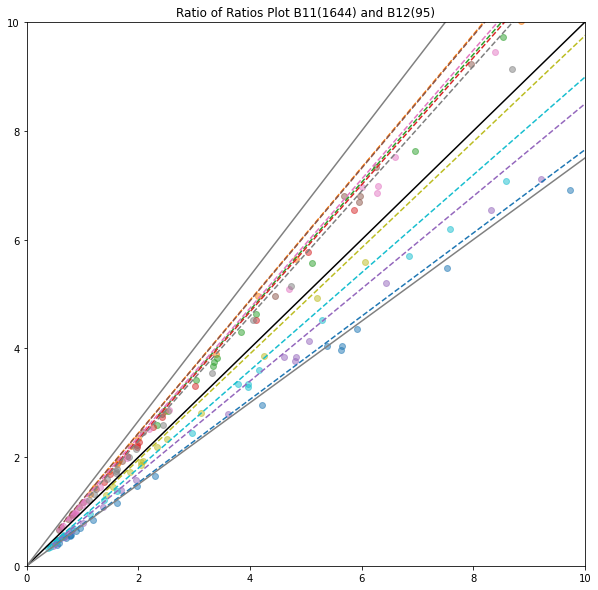

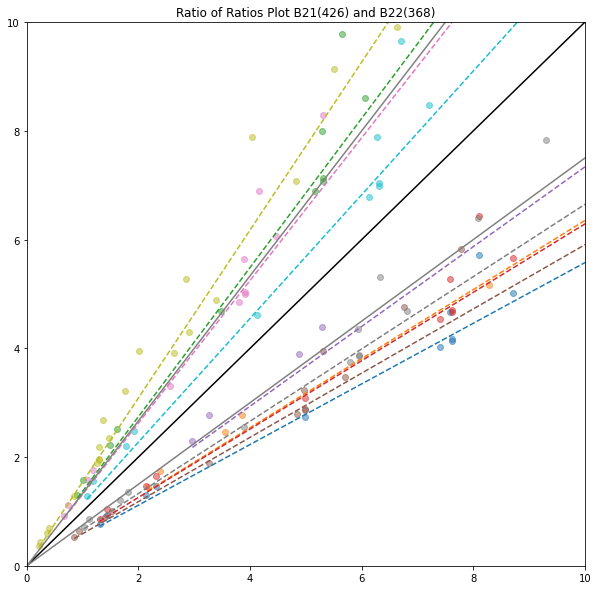

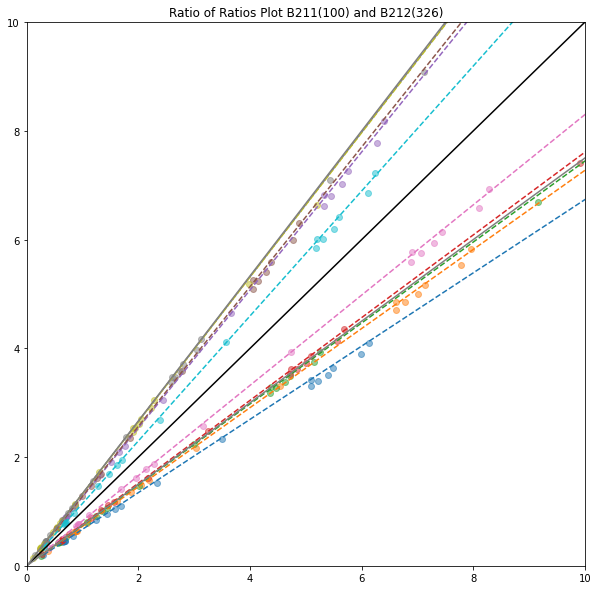

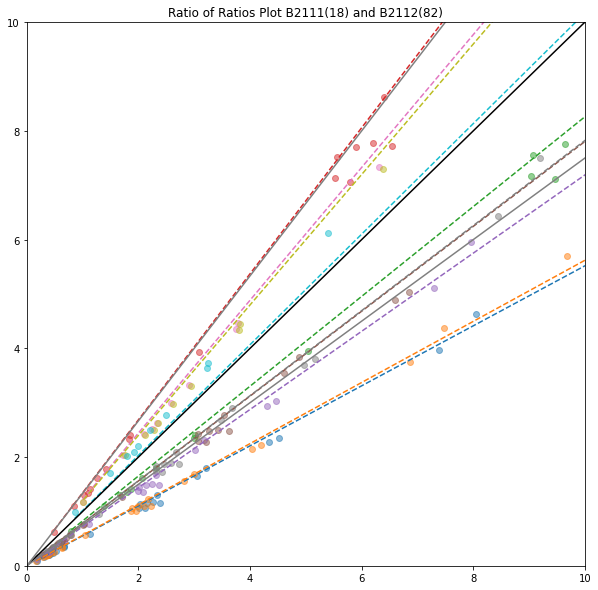

...

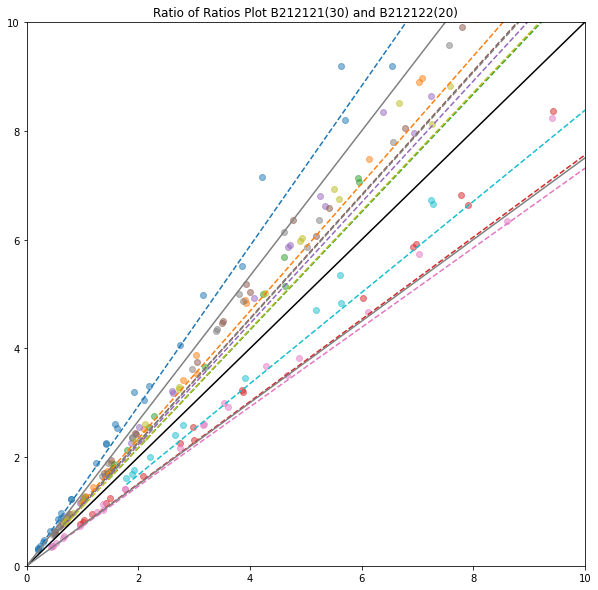

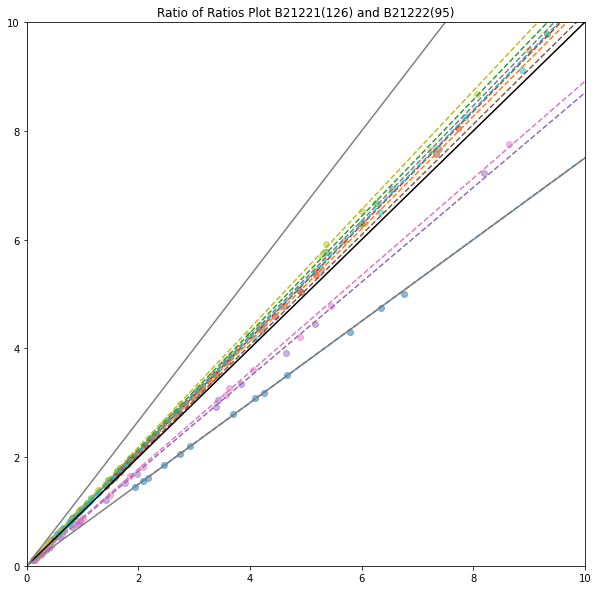

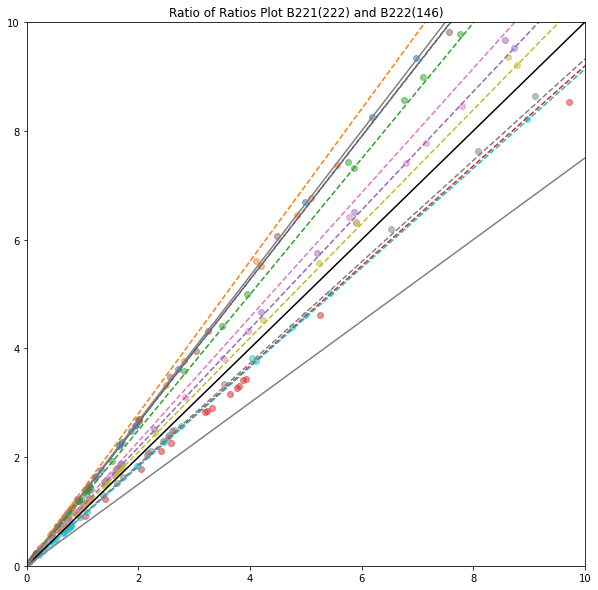

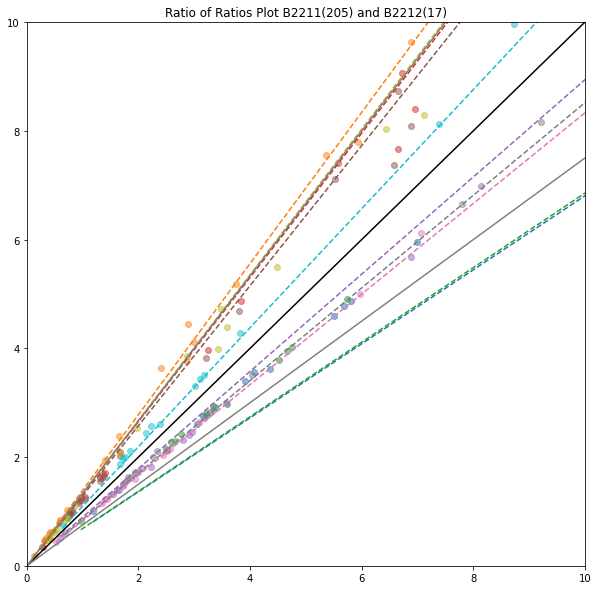

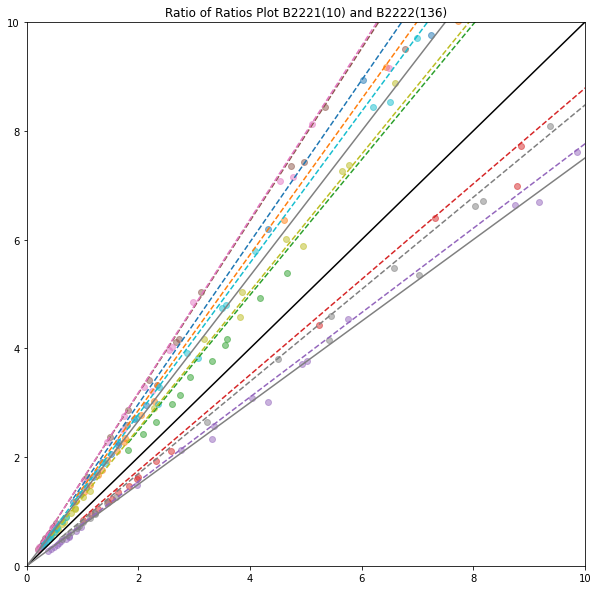

In [44]:
final_populations_2 = recursive_em_split(all_data, cells,threshold=3/4, max_depth=10, current_depth=0, name="B")

In [45]:
for B in final_populations_2:
    print(B, len(final_populations_2[B]["cells"]))

B1 1739
B211 100
B21211 55
B21212 50
B2122 221
B221 222
B222 146


In [46]:
for A in final_populations:
    print(A, len(final_populations[A]["cells"]))

A111 145
A112 220
A121 95
A12211 55
A122121 26
A122122 28
A12221 92
A12222 129
A2 1743


In [47]:
from scipy.special import logsumexp
#Reassign cells to populations based on closest multinomial parameters
def reassign_cells(data, populations):
    """
    Reassigns cells to populations based on closest multinomial parameters.
    
    Parameters:
    - data: the full genomic data
    - populations: dictionary of populations with their cells and mult_KV parameters
    
    Returns:
    - Dictionary with updated cell assignments for each population
    """
    
    # Extract multinomial parameters for each population
    pop_params = {pop: populations[pop]['mult_KV'] for pop in populations}
    
    # Prepare a new dictionary to hold reassigned cells
    new_populations = {pop: {"cells": [], "mult_KV": populations[pop]["mult_KV"]} for pop in populations}

    # Iterate over each cell in the data
    for cell in data.columns:
        cell_data = data[cell].values
        # Compute log-likelihoods for the cell under each population's multinomial parameters
        log_likelihoods = {}
        for pop, params in pop_params.items():
            log_probs = np.log(params + 1e-10)  # Add small value to avoid log(0)
            log_likelihood = np.sum(cell_data * log_probs)
            log_likelihoods[pop] = log_likelihood
        # Subtract max log-likelihood for numerical stability   
        max_log_likelihood = max(log_likelihoods.values())
        for pop in log_likelihoods:
            log_likelihoods[pop] -= max_log_likelihood
        # Assign the cell to the population with the highest log-likelihood
        best_pop = max(log_likelihoods, key=log_likelihoods.get)
        new_populations[best_pop]["cells"].append(cell)

    

    return new_populations
reassigned_populations = reassign_cells(all_data, final_populations)
reassigned_populations_2 = reassign_cells(all_data, final_populations_2)

In [48]:
def print_overlap_matrix(pop1, pop2, name1="A", name2="B"):
    """
    Print overlap matrix showing number of shared cells between populations
    """
    pop1_names = sorted(pop1.keys())
    pop2_names = sorted(pop2.keys())
    
    # Print header
    print(f"\nOverlap Matrix ({name1} rows vs {name2} cols):")
    print("=" * 50)
    print(f"{'Pop':<8}", end="")
    for pop_b in pop2_names:
        print(f"{pop_b:>8}", end="")
    print()
    
    # Print overlap counts
    for pop_a in pop1_names:
        cells_a = set(pop1[pop_a]["cells"])
        print(f"{pop_a:<8}", end="")
        
        for pop_b in pop2_names:
            cells_b = set(pop2[pop_b]["cells"])
            overlap = len(cells_a.intersection(cells_b))
            print(f"{overlap:>8}", end="")
        print()

In [49]:
print_overlap_matrix(reassigned_populations, reassigned_populations_2, "A", "B")


Overlap Matrix (A rows vs B cols):
Pop           B1    B211  B21211  B21212   B2122    B221    B222
A111           0       0       0       1       0       1     142
A112           0       0       0       0       0     222       2
A121           0      83       0       0       0       0       0
A12211         0       0      42       0       1       0       0
A122121       20       3       3      28       0       1       2
A122122        0       3       0      31       4       0       0
A12221         0       1       8       5      89       0       0
A12222         0       0       0       2     124       0       0
A2          1715       0       0       0       0       0       0


In [50]:
print_overlap_matrix(reassigned_populations, final_populations, "newA", "oldA")


Overlap Matrix (newA rows vs oldA cols):
Pop         A111    A112    A121  A12211 A122121 A122122  A12221  A12222      A2
A111         144       0       0       0       0       0       0       0       0
A112           0     218       0       0       0       0       0       0       6
A121           0       0      83       0       0       0       0       0       0
A12211         0       0       1      42       0       0       0       0       0
A122121        1       1       6       0      26       0       1       0      22
A122122        0       1       3       0       0      28       2       4       0
A12221         0       0       1      13       0       0      89       0       0
A12222         0       0       1       0       0       0       0     125       0
A2             0       0       0       0       0       0       0       0    1715


In [51]:
# Save normal population cells
normal_population_cells = reassigned_populations[min_dev_pop]["cells"]
# with open(folder+tumor+".normal_cells_EM.txt", "w") as f:
#     for cell in normal_population_cells:
#         f.write(cell + "\n")

In [52]:
#Compare populations to normal population
def make_unif_dict(all_data, reassigned_populations):
    """
    Make uniformity dictionary for each population.
    """
    unif_dict = {}
    dev_from_median = {}
    for pop in reassigned_populations:
        pop_cells = reassigned_populations[pop]["cells"]
        pop_data = all_data[pop_cells]
        unif = pop_data.sum(axis = 1)/data["lengths"]
        unif = unif/np.median(unif)
        # plt.hist(unif, bins = 20, alpha = 0.5, label = pop)
        # plt.xlim([0,5])
        unif_dict[pop] = unif
        dev_from_median[pop] = np.median(np.abs(unif - 1))
        #plt.title(f"Population {pop} with {len(pop_cells)} cells")
        #plt.show()
    min_dev_pop = min(dev_from_median, key=dev_from_median.get)
    return unif_dict, min_dev_pop

        




In [53]:
unif_1, normal_1 = make_unif_dict(all_data, reassigned_populations)
unif_2, normal_2 = make_unif_dict(all_data, reassigned_populations_2)

In [54]:
def compute_average_segment_counts(all_data, populations):
    """
    Compute average readcount per cell in each segment for each population,
    and ratios relative to the normal population.
    
    Parameters:
    - all_data: DataFrame with segments as rows and cells as columns
    - populations: Dictionary of populations with their cell lists
    
    Returns:
    - avg_seg_count: DataFrame with segments as rows and populations as columns (average counts)
    - ratios_to_normal: DataFrame with segments as rows and populations as columns (ratios to normal)
    - normal_pop_name: Name of the identified normal population
    """
    
    # Use existing function to identify normal population
    unif_dict, normal_pop_name = make_unif_dict(all_data, populations)
    print(f"Normal population identified as: {normal_pop_name}")
    
    # Create average segment counts dataframe
    avg_seg_count = pd.DataFrame()
    
    # Add segment information
    avg_seg_count['chrom'] = data['chrom'].values
    avg_seg_count['start'] = data['abstart'].values  
    avg_seg_count['end'] = data['abend'].values
    avg_seg_count['segment_id'] = range(len(data))
    
    # Compute average counts for each population
    for pop_name, pop_data in populations.items():
        cells_in_pop = pop_data["cells"]
        
        if len(cells_in_pop) > 0:
            # Sum counts across all cells in the population, then divide by number of cells
            pop_segment_data = all_data[cells_in_pop]
            avg_counts = pop_segment_data.sum(axis=1) / len(cells_in_pop)
            avg_seg_count[pop_name] = avg_counts
        else:
            # Handle empty populations
            avg_seg_count[pop_name] = 0
    
    # Create ratios to normal dataframe
    ratios_to_normal = pd.DataFrame()
    
    # Add segment information
    ratios_to_normal['chrom'] = avg_seg_count['chrom']
    ratios_to_normal['start'] = avg_seg_count['start']
    ratios_to_normal['end'] = avg_seg_count['end']
    ratios_to_normal['segment_id'] = avg_seg_count['segment_id']
    
    # Get normal population average counts as baseline
    normal_avg_counts = avg_seg_count[normal_pop_name]
    
    for pop_col, _ in populations.items():
        if pop_col == normal_pop_name:
            # Normal population ratio to itself should be 1
            ratios_to_normal[f"{pop_col}_ratio"] = 1.0
        else:
            # Avoid division by zero - add small epsilon where normal counts are zero
            epsilon = 1e-10
            safe_normal_counts = normal_avg_counts + epsilon
            ratios_to_normal[f"{pop_col}_ratio"] = avg_seg_count[pop_col] / safe_normal_counts
    
    return avg_seg_count, ratios_to_normal, normal_pop_name



In [55]:
avg_seg_count_1, ratios_to_normal_1, normal_pop_name_1 = compute_average_segment_counts(all_data, reassigned_populations)
avg_seg_count_2, ratios_to_normal_2, normal_pop_name_2 = compute_average_segment_counts(all_data, reassigned_populations_2)

Normal population identified as: A2
Normal population identified as: B1


In [56]:
ratios_to_normal_1

,chrom,start,end,segment_id,A111_ratio,A112_ratio,A121_ratio,A12211_ratio,A122121_ratio,A122122_ratio,A12221_ratio,A12222_ratio,A2_ratio
0,chr1,0,45387037,0,0.929183,0.985224,0.905063,0.913830,1.150927,0.930847,0.964235,0.970523,1.0
1,chr1,45972336,119478274,1,1.780177,1.859744,1.710268,1.712968,1.548052,1.681488,1.797175,1.778380,1.0
2,chr1,120035598,175362842,2,1.418750,1.498314,2.373248,1.949503,1.927657,2.218317,2.432337,2.432078,1.0
3,chr1,175900450,182029442,3,1.340086,1.053842,1.709137,2.305407,1.583529,1.606577,1.746633,1.768576,1.0
4,chr1,182578512,248389233,4,0.907918,0.985492,0.874476,1.258017,1.123535,0.845963,0.887135,0.886606,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,chr22,2853982439,2860306560,84,0.797705,0.830081,0.692203,0.806516,1.047693,0.740814,0.775234,0.766201,1.0
85,chr22,2860858981,2880367224,85,1.327859,1.389160,1.226240,1.290507,1.389211,1.296693,1.268937,1.288406,1.0
86,chrX,2881033287,2933937372,86,1.816109,1.407067,1.321280,1.746728,1.390854,1.175707,1.304952,1.341933,1.0
87,chrX,2934589219,2968652200,87,1.478492,1.413036,1.740359,1.773745,1.535155,1.631142,1.773435,1.760023,1.0


In [57]:
def plot_copy_number_step_function(ratios_df, pop_cols, title="Copy Number Comparison"):
    """
    Plot copy number ratios as step functions with chromosome boundaries.
    All populations are superimposed on the same plot.
    
    Parameters:
    - ratios_df: DataFrame with ratio data (ratios_to_normal_1)
    - pop_cols: List of population column names (e.g., ['A1111_ratio', 'A1112_ratio'])
    - title: Plot title
    """
    
    # Sort data by chromosome and position
    plot_data = ratios_df.copy()
    
    # Define chromosome order
    chrom_order = ['chr' + str(i) for i in range(1, 23)] + ['chrX']
    plot_data['chrom_num'] = plot_data['chrom'].apply(
        lambda x: chrom_order.index(x) if x in chrom_order else 999
    )
    plot_data = plot_data.sort_values(['chrom_num', 'start']).reset_index(drop=True)
    
    # Calculate segment lengths and cumulative positions
    plot_data['length'] = plot_data['end'] - plot_data['start']
    plot_data['cum_start'] = 0
    plot_data['cum_end'] = 0
    
    cum_pos = 0
    chrom_boundaries = []
    chrom_centers = []
    chrom_labels = []
    
    for chrom in chrom_order:
        if chrom in plot_data['chrom'].values:
            chrom_data = plot_data[plot_data['chrom'] == chrom]
            
            # Set cumulative positions for this chromosome
            chrom_start = cum_pos
            for idx in chrom_data.index:
                plot_data.loc[idx, 'cum_start'] = cum_pos
                cum_pos += plot_data.loc[idx, 'length']
                plot_data.loc[idx, 'cum_end'] = cum_pos
            
            # Record chromosome boundaries and centers
            chrom_end = cum_pos
            chrom_boundaries.append(chrom_end)
            chrom_centers.append((chrom_start + chrom_end) / 2)
            chrom_labels.append(chrom.replace('chr', ''))
            
            # Add small gap between chromosomes
            cum_pos += max(plot_data['length']) * 0.02  # 2% of max segment length
    
    # Create single plot
    fig, ax = plt.subplots(1, 1, figsize=(20, 8))
    
    # Define colors for different populations
    colors = ['blue', 'red', 'green', 'purple', 'orange', 'brown', 'pink', 'gray']
    
    # Plot each population on the same axes
    for pop_idx, pop_col in enumerate(pop_cols):
        color = colors[pop_idx % len(colors)]
        pop_label = pop_col.replace("_ratio", "")
        
        # Plot step function for this population
        for idx, row in plot_data.iterrows():
            x_coords = [row['cum_start'], row['cum_end']]
            y_coords = [row[pop_col], row[pop_col]]
            
            # Add label only to first segment of each population
            label = pop_label if idx == 0 else None
            ax.plot(x_coords, y_coords, color=color, linewidth=2, label=label)
            
            # Connect segments with vertical lines within same chromosome
            if idx > 0:
                prev_row = plot_data.iloc[idx-1]
                if row['chrom'] == prev_row['chrom']:  # Same chromosome
                    ax.plot([prev_row['cum_end'], row['cum_start']], 
                           [prev_row[pop_col], row[pop_col]], color=color, linewidth=1)
    
    # Add chromosome boundary lines
    for boundary in chrom_boundaries[:-1]:  # Don't add line after last chromosome
        ax.axvline(x=boundary, color='gray', linestyle='--', alpha=0.7)
    
    # Add reference lines for copy numbers
    ax.axhline(y=1, color='black', linestyle='-', alpha=0.5, label='Normal (2 copies)')
    ax.axhline(y=1.5, color='lightgray', linestyle=':', alpha=0.5)
    ax.axhline(y=0.5, color='lightgray', linestyle=':', alpha=0.5)
    ax.axhline(y=2, color='lightgray', linestyle=':', alpha=0.5)
    ax.axhline(y=0, color='red', linestyle=':', alpha=0.5)

    # Set title and labels
    ax.set_title(title, fontsize=16)
    ax.set_ylabel('Copy Number Ratio', fontsize=14)
    ax.set_xlabel('Chromosome', fontsize=14)
    
    # Set y-axis limits based on all populations
    all_ratios = []
    for pop_col in pop_cols:
        all_ratios.extend(plot_data[pop_col].values)
    
    y_max = max(all_ratios) * 1.1
    y_min = max(0, min(all_ratios) * 0.9)  # Don't go below 0
    ax.set_ylim(y_min, y_max)
    
    # Set chromosome labels on x-axis
    ax.set_xticks(chrom_centers)
    ax.set_xticklabels(chrom_labels, rotation=0)
    
    # Add legend
    ax.legend(loc='upper right')
    
    plt.tight_layout()
    plt.show()



In [58]:
pop_names = ratios_to_normal_1.columns[4:]

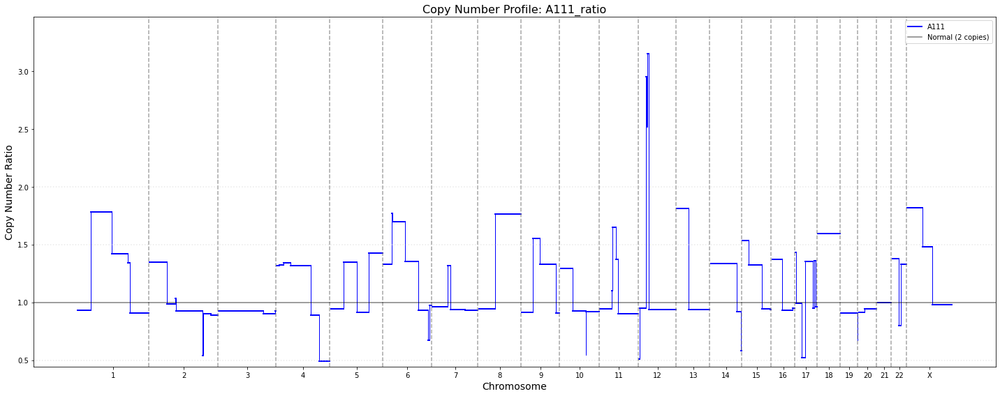

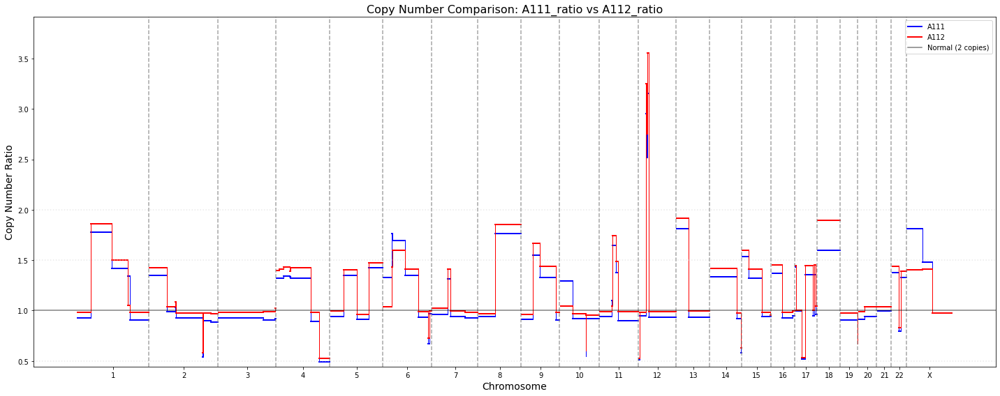

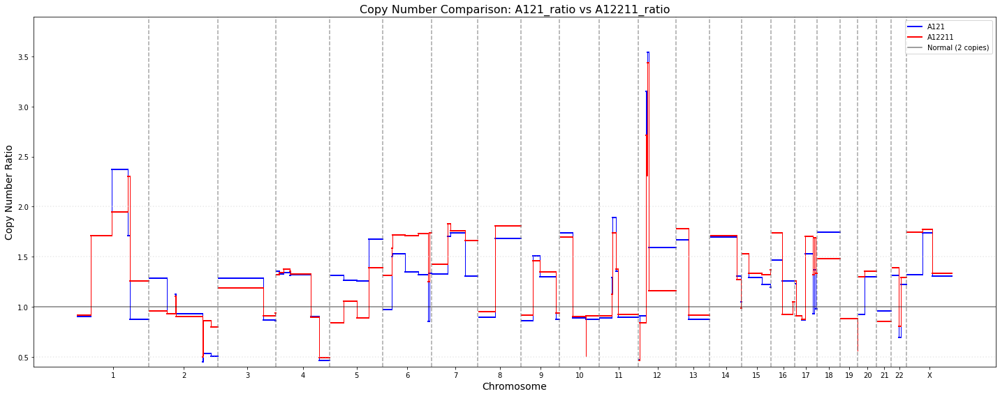

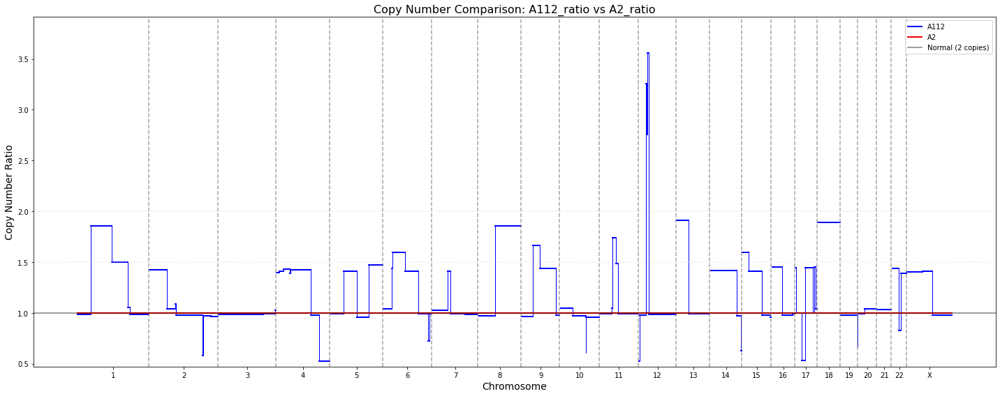

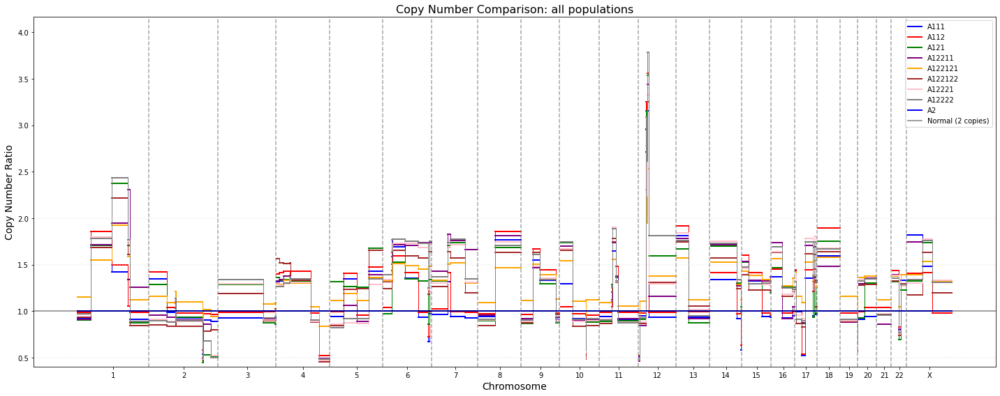

In [60]:
# Example usage:

# Plot just one population
plot_copy_number_step_function(
    ratios_to_normal_1, 
    [pop_names[0]], 
    'Copy Number Profile: '+ pop_names[0]
)

# Plot two populations
plot_copy_number_step_function(
    ratios_to_normal_1, 
    [pop_names[0], pop_names[1]], 
    'Copy Number Comparison: '+ pop_names[0] + ' vs ' + pop_names[1]
)

# Plot two populations
plot_copy_number_step_function(
    ratios_to_normal_1, 
    [pop_names[2], pop_names[3]], 
    'Copy Number Comparison: '+ pop_names[2] + ' vs ' + pop_names[3]
    
)

# Plot two populations
plot_copy_number_step_function(
    ratios_to_normal_1, 
    [pop_names[1], pop_names[-1]], 
    'Copy Number Comparison: ' + pop_names[1] + ' vs ' + pop_names[-1]
)

# Plot two all
plot_copy_number_step_function(
    ratios_to_normal_1, 
    pop_names, 
    'Copy Number Comparison: all populations'
)



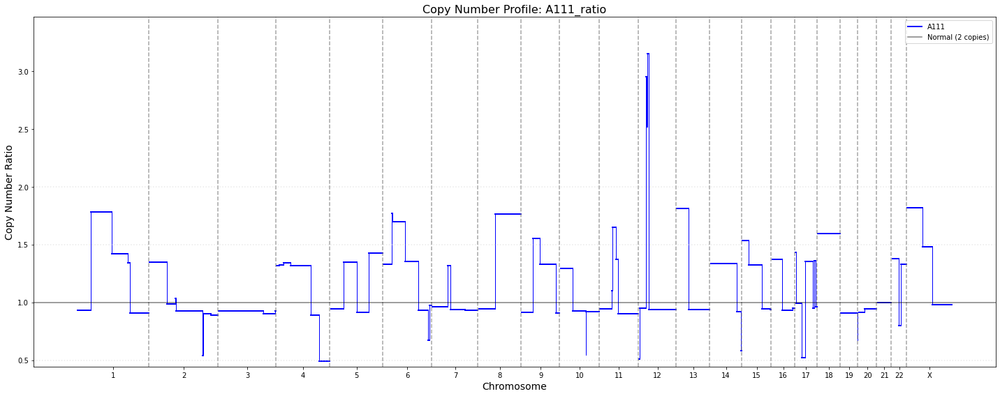

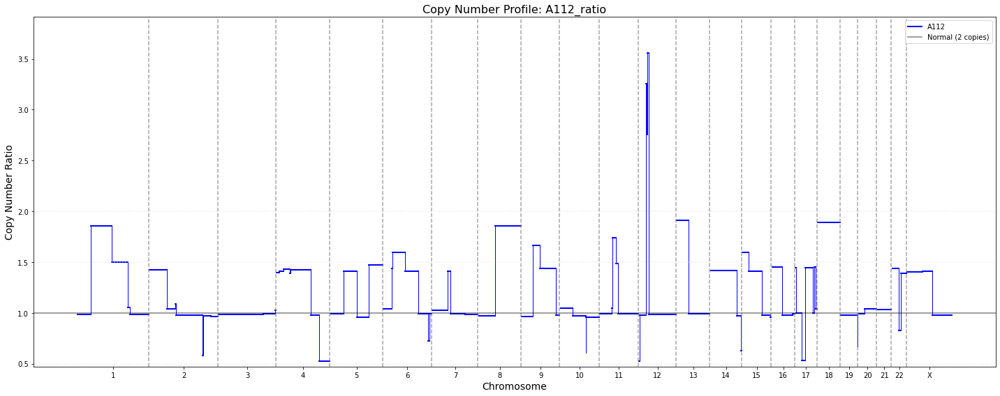

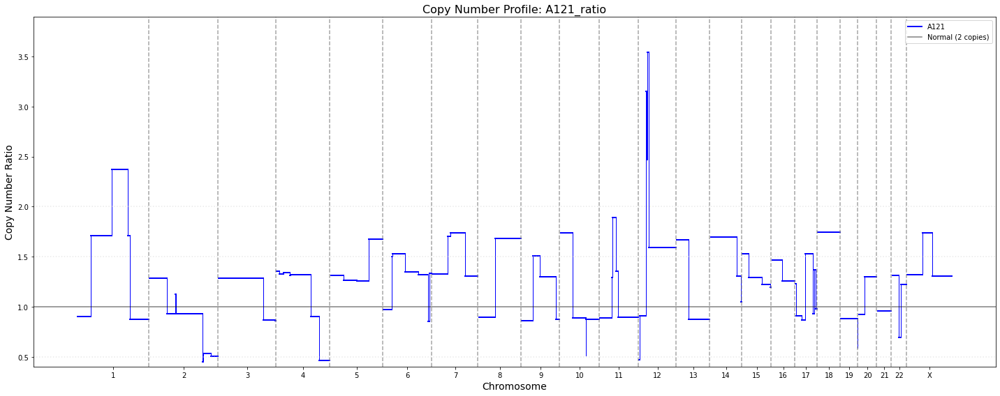

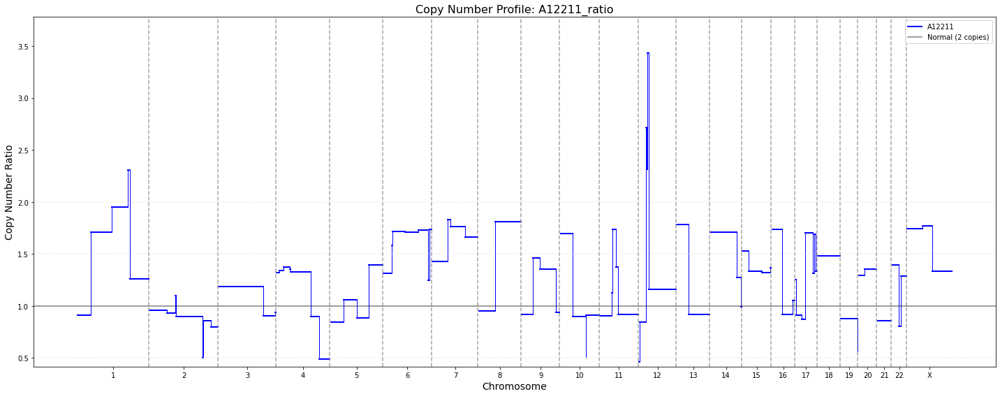

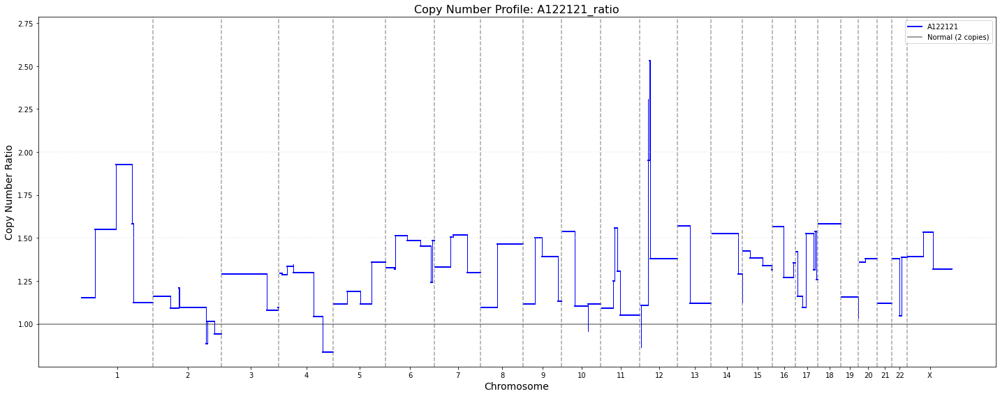

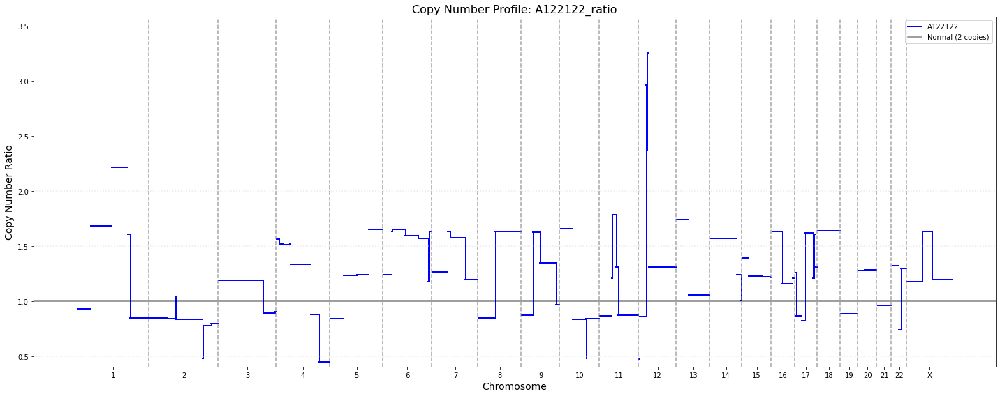

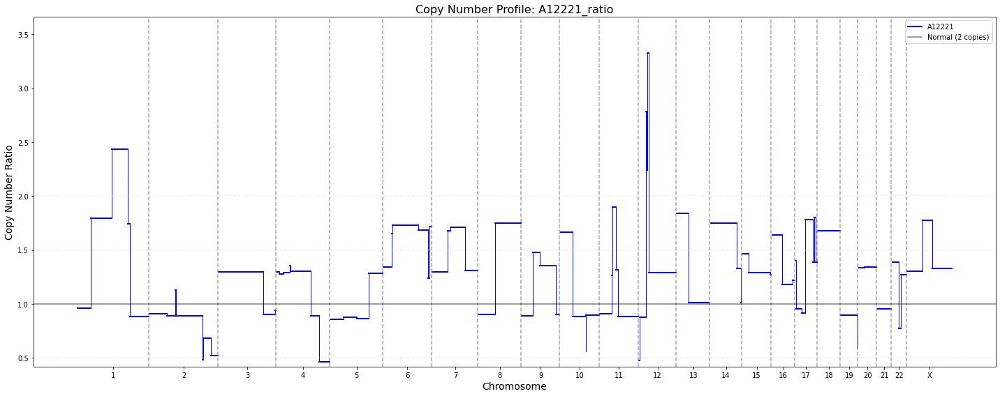

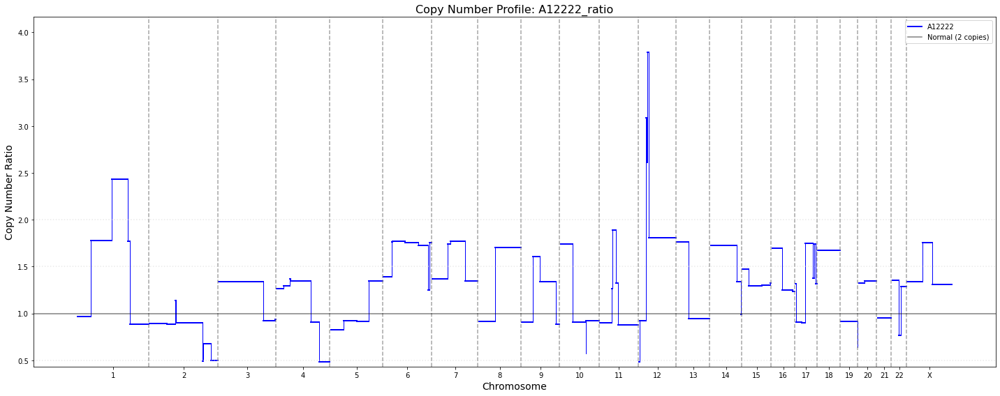

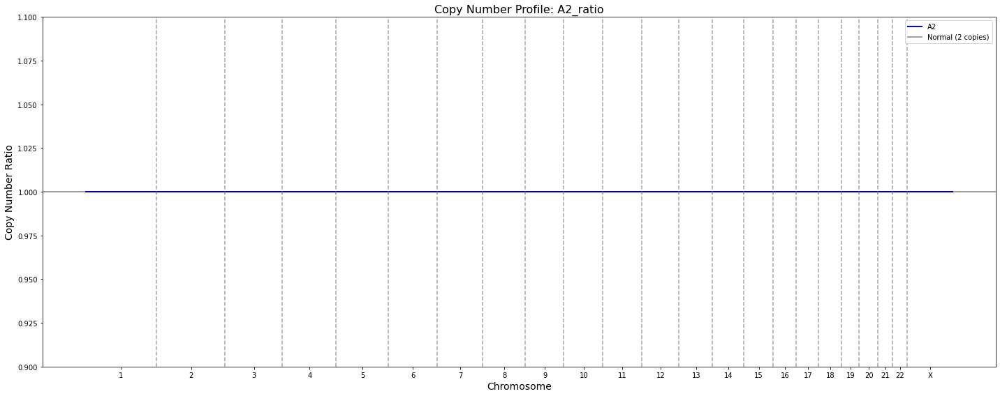

In [61]:
for pop in pop_names:
    plot_copy_number_step_function(
    ratios_to_normal_1, 
    [pop], 
    'Copy Number Profile: '+ pop
)

In [62]:
def compute_optimal_ploidy_and_profile(ratios_df, pop_col, m_range=[1.5, 6], step_size=0.1, plot=True):
    """
    Compute optimal ploidy multiplier and integer copy number profile for a population.
    
    Parameters:
    - ratios_df: DataFrame with ratio data and segment information
    - pop_col: Column name for the population ratios (e.g., 'A1111_ratio')
    - m_range: Range of multipliers to test as [min, max] (default: [1.5, 6])
    - step_size: Step size for multiplier range (default: 0.1)
    - plot: Whether to plot the optimization results
    
    Returns:
    - optimal_m: Best multiplier value
    - min_cost: Minimum cost achieved
    - results_df: DataFrame with scaled and integer copy number profiles
    - cost_results: Dictionary of all tested multipliers and their costs
    """
    
    # Create range of multipliers to test
    m_values = np.arange(m_range[0], m_range[1] + step_size, step_size)
    
    # Get ratios and segment lengths
    ratios = ratios_df[pop_col].values
    lengths = (ratios_df['end'] - ratios_df['start']).values
    
    cost_results = {}
    
    # Test each multiplier
    for m in m_values:
        # Compute integer copy numbers
        scaled_ratios = m * ratios
        integer_copies = np.round(scaled_ratios).astype(int)
        
        # Compute weighted cost: sum of length * (scaled_ratio - integer)^2
        deviations = scaled_ratios - integer_copies
        weighted_deviations_squared = lengths * (deviations ** 2)
        total_cost = np.sum(weighted_deviations_squared)
        
        cost_results[m] = total_cost
    
    # Find optimal multiplier
    optimal_m = min(cost_results.keys(), key=lambda x: cost_results[x])
    min_cost = cost_results[optimal_m]
    
    # Compute integer profile with optimal multiplier
    optimal_scaled_ratios = optimal_m * ratios
    integer_profile = np.round(optimal_scaled_ratios).astype(int)
    
    # Create results DataFrame
    results_df = ratios_df[['chrom', 'start', 'end']].copy()
    results_df[f'{pop_col}_scaled'] = optimal_scaled_ratios
    results_df[f'{pop_col}_integer'] = integer_profile
    
    if plot:
        # Sort data by chromosome and position for plotting
        plot_data = results_df.copy()
        
        # Define chromosome order
        chrom_order = ['chr' + str(i) for i in range(1, 23)] + ['chrX']
        plot_data['chrom_num'] = plot_data['chrom'].apply(
            lambda x: chrom_order.index(x) if x in chrom_order else 999
        )
        plot_data = plot_data.sort_values(['chrom_num', 'start']).reset_index(drop=True)
        
        # Calculate cumulative positions
        plot_data['length'] = plot_data['end'] - plot_data['start']
        cum_pos = 0
        chrom_boundaries = []
        chrom_centers = []
        chrom_labels = []
        
        for chrom in chrom_order:
            if chrom in plot_data['chrom'].values:
                chrom_data = plot_data[plot_data['chrom'] == chrom]
                
                # Set cumulative positions for this chromosome
                chrom_start = cum_pos
                for idx in chrom_data.index:
                    plot_data.loc[idx, 'cum_start'] = cum_pos
                    cum_pos += plot_data.loc[idx, 'length']
                    plot_data.loc[idx, 'cum_end'] = cum_pos
                
                # Record chromosome boundaries and centers
                chrom_end = cum_pos
                chrom_boundaries.append(chrom_end)
                chrom_centers.append((chrom_start + chrom_end) / 2)
                chrom_labels.append(chrom.replace('chr', ''))
                
                # Add small gap between chromosomes
                cum_pos += max(plot_data['length']) * 0.02
        
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(20, 12))
        
        # Plot cost function
        m_plot_values = list(cost_results.keys())
        costs = list(cost_results.values())
        
        ax1.plot(m_plot_values, costs, 'b-', linewidth=2)
        ax1.axvline(x=optimal_m, color='red', linestyle='--', 
                   label=f'Optimal m = {optimal_m:.2f}')
        ax1.set_xlabel('Multiplier (m)')
        ax1.set_ylabel('Weighted Cost')
        ax1.set_title(f'Ploidy Optimization for {pop_col.replace("_ratio", "")}')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # Plot step functions for scaled and integer copy numbers
        scaled_col = f'{pop_col}_scaled'
        integer_col = f'{pop_col}_integer'
        
        # Plot scaled copy numbers
        for idx, row in plot_data.iterrows():
            x_coords = [row['cum_start'], row['cum_end']]
            y_coords = [row[scaled_col], row[scaled_col]]
            
            # Add label only to first segment
            label = 'Scaled Copy Number' if idx == 0 else None
            ax2.plot(x_coords, y_coords, color='blue', linewidth=2, alpha=0.7, label=label)
            
            # Connect segments with vertical lines within same chromosome
            if idx > 0:
                prev_row = plot_data.iloc[idx-1]
                if row['chrom'] == prev_row['chrom']:
                    ax2.plot([prev_row['cum_end'], row['cum_start']], 
                           [prev_row[scaled_col], row[scaled_col]], color='blue', linewidth=1, alpha=0.7)
        
        # Plot integer copy numbers
        for idx, row in plot_data.iterrows():
            x_coords = [row['cum_start'], row['cum_end']]
            y_coords = [row[integer_col], row[integer_col]]
            
            # Add label only to first segment
            label = 'Integer Copy Number' if idx == 0 else None
            ax2.plot(x_coords, y_coords, color='red', linewidth=2, alpha=0.8, label=label)
            
            # Connect segments with vertical lines within same chromosome
            if idx > 0:
                prev_row = plot_data.iloc[idx-1]
                if row['chrom'] == prev_row['chrom']:
                    ax2.plot([prev_row['cum_end'], row['cum_start']], 
                           [prev_row[integer_col], row[integer_col]], color='red', linewidth=1, alpha=0.8)
        
        # Add chromosome boundary lines
        for boundary in chrom_boundaries[:-1]:
            ax2.axvline(x=boundary, color='gray', linestyle='--', alpha=0.5)
        
        # Add reference lines for copy numbers
        ax2.axhline(y=2, color='black', linestyle='-', alpha=0.5, label='Normal (2 copies)')
        ax2.axhline(y=1, color='lightgray', linestyle=':', alpha=0.5)
        ax2.axhline(y=3, color='lightgray', linestyle=':', alpha=0.5)
        ax2.axhline(y=4, color='lightgray', linestyle=':', alpha=0.5)
        
        # Set labels and formatting
        ax2.set_title(f'Copy Number Profile: {pop_col.replace("_ratio", "")}\nOptimal m = {optimal_m:.2f}')
        ax2.set_ylabel('Copy Number', fontsize=12)
        ax2.set_xlabel('Chromosome', fontsize=12)
        
        # Set chromosome labels on x-axis
        ax2.set_xticks(chrom_centers)
        ax2.set_xticklabels(chrom_labels, rotation=0)
        
        # Set y-axis limits
        all_values = list(plot_data[scaled_col]) + list(plot_data[integer_col])
        y_max = max(all_values) * 1.1
        y_min = max(0, min(all_values) * 0.9)
        ax2.set_ylim(y_min, y_max)
        
        ax2.legend(loc='upper right')
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
        
        # Print summary
        total_length = np.sum(lengths)
        avg_copy_number = np.sum(integer_profile * lengths) / total_length
        
        print(f"\nOptimal Results for {pop_col.replace('_ratio', '')}:")
        print(f"Optimal multiplier (m): {optimal_m:.3f}")
        print(f"Minimum cost: {min_cost:.2e}")
        print(f"Average copy number: {avg_copy_number:.2f}")
    
    return optimal_m, min_cost, results_df, cost_results

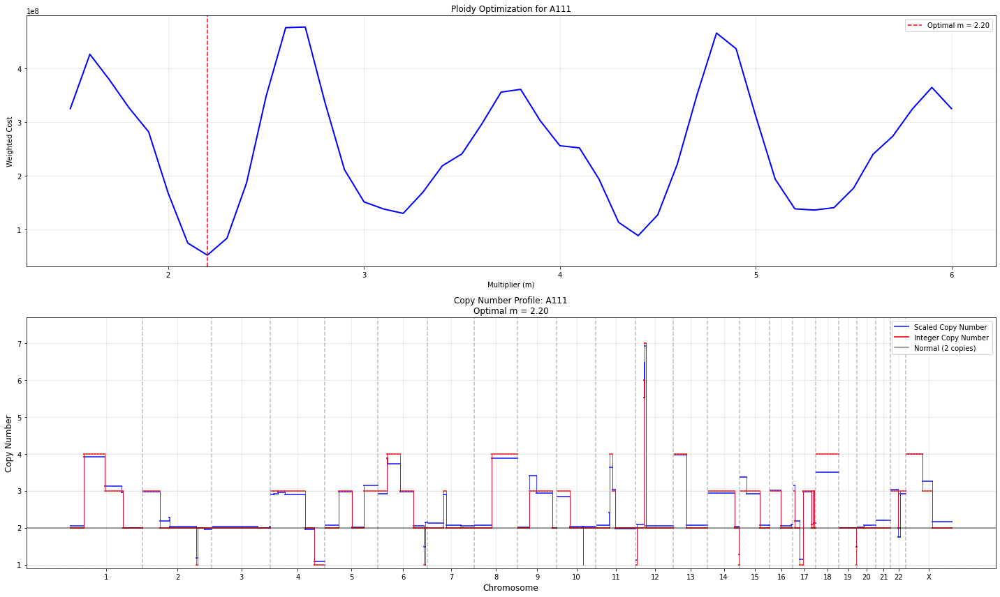


Optimal Results for A111:
Optimal multiplier (m): 2.200
Minimum cost: 5.26e+07
Average copy number: 2.54



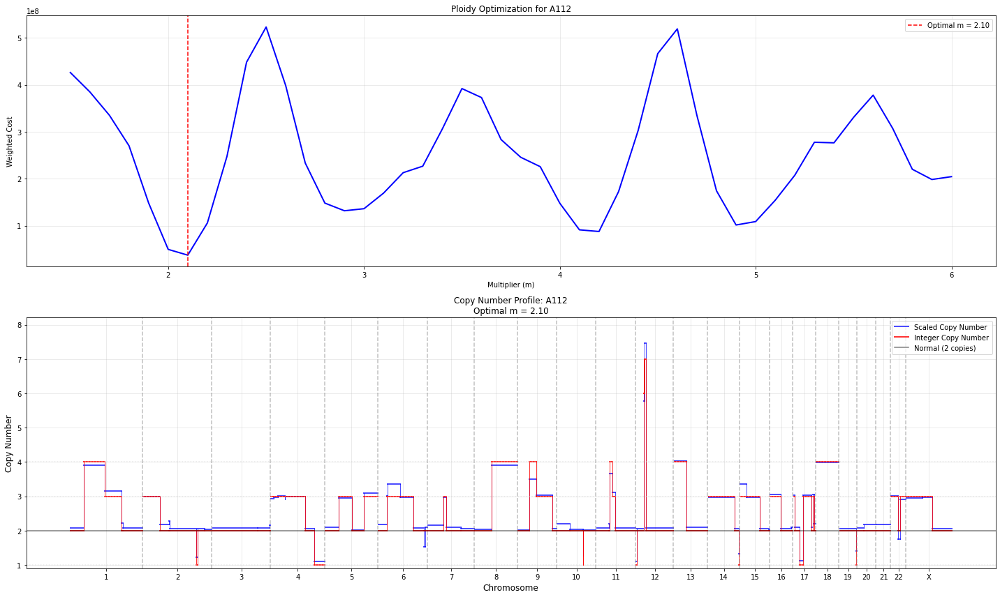


Optimal Results for A112:
Optimal multiplier (m): 2.100
Minimum cost: 3.72e+07
Average copy number: 2.49



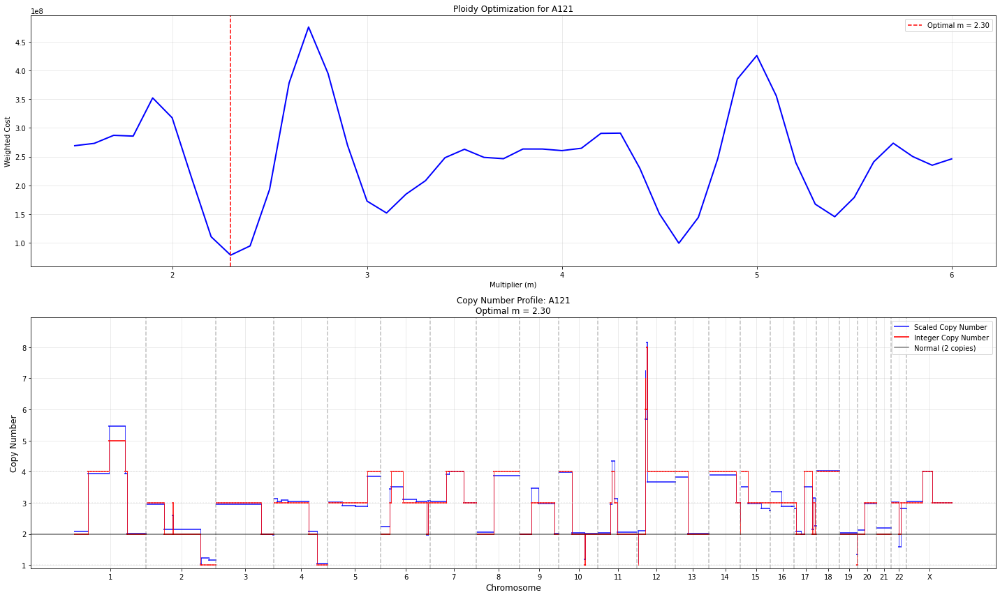


Optimal Results for A121:
Optimal multiplier (m): 2.300
Minimum cost: 7.86e+07
Average copy number: 2.93



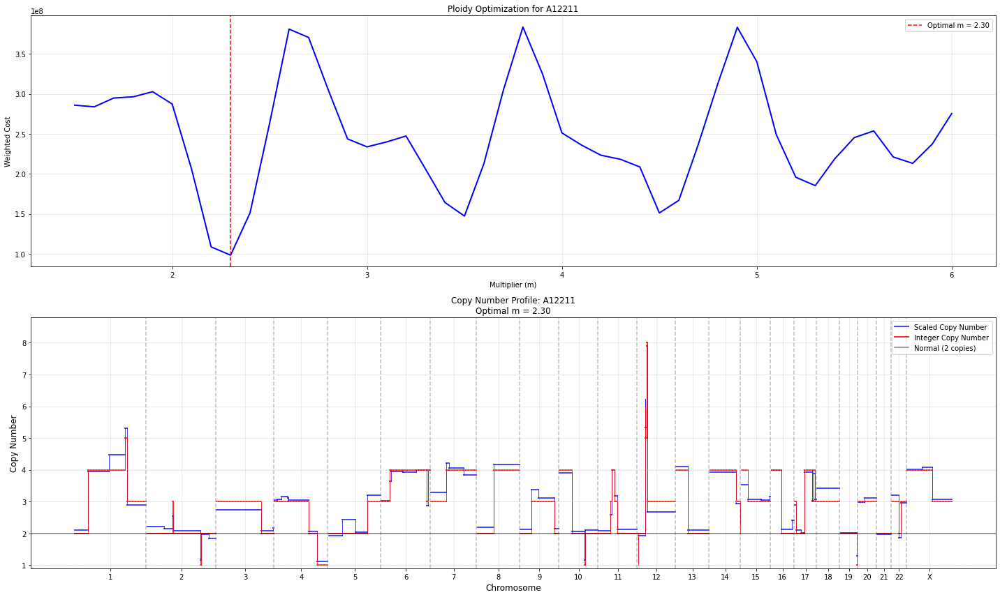


Optimal Results for A12211:
Optimal multiplier (m): 2.300
Minimum cost: 9.84e+07
Average copy number: 2.90



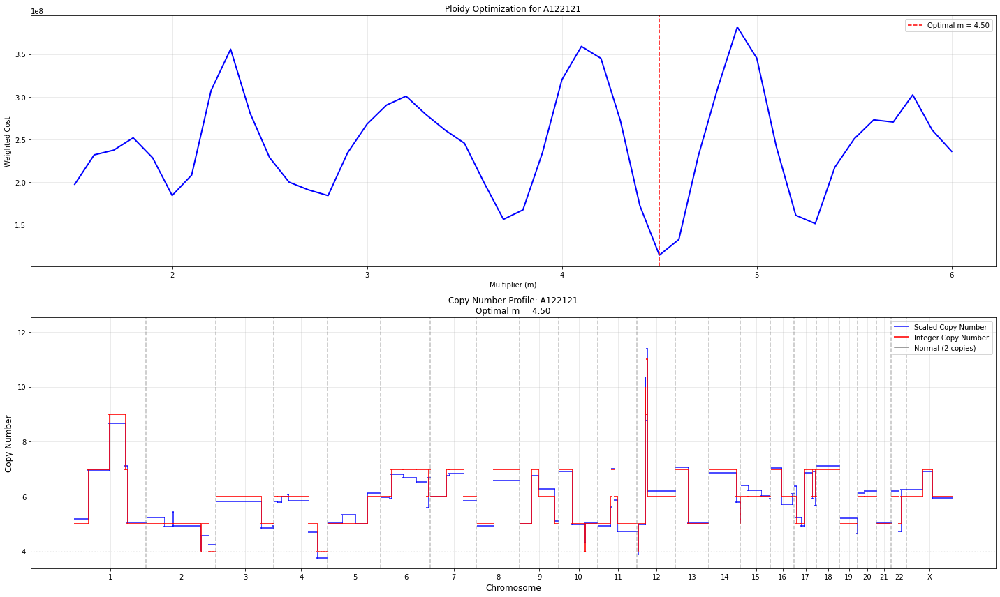


Optimal Results for A122121:
Optimal multiplier (m): 4.500
Minimum cost: 1.15e+08
Average copy number: 5.91



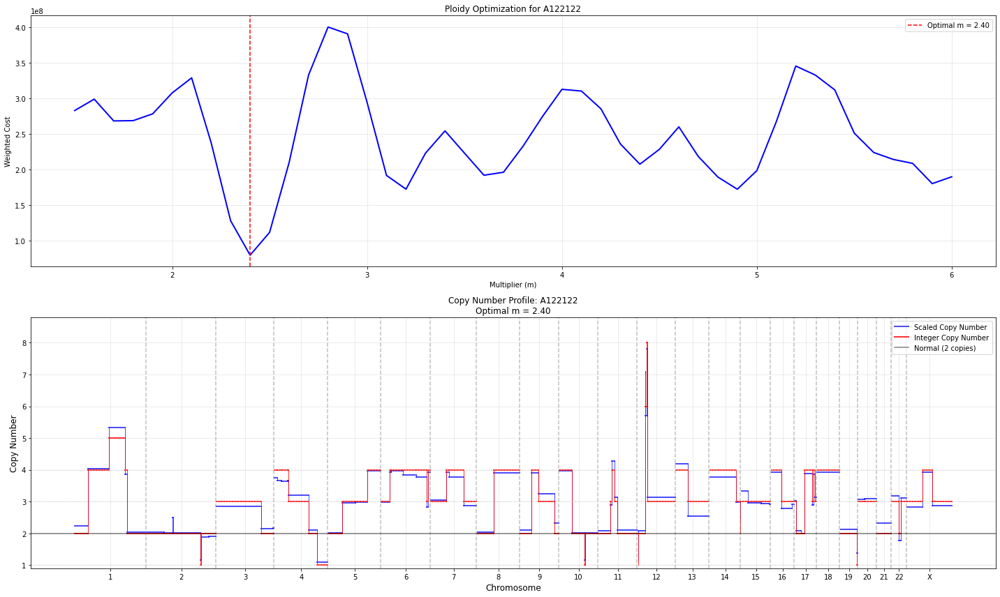


Optimal Results for A122122:
Optimal multiplier (m): 2.400
Minimum cost: 7.93e+07
Average copy number: 2.99



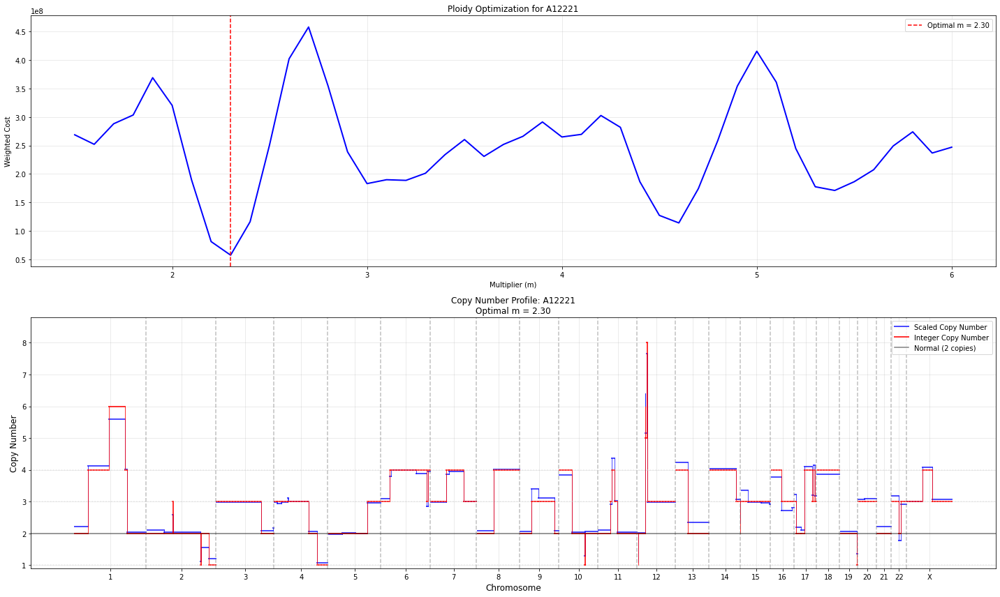


Optimal Results for A12221:
Optimal multiplier (m): 2.300
Minimum cost: 5.75e+07
Average copy number: 2.90



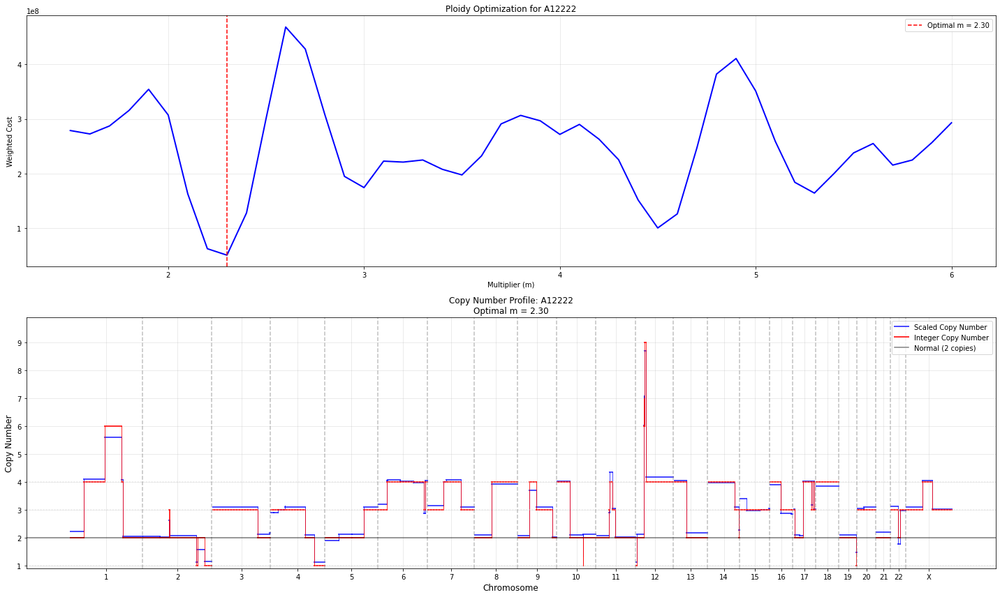


Optimal Results for A12222:
Optimal multiplier (m): 2.300
Minimum cost: 5.11e+07
Average copy number: 2.94


In [63]:
# Example usage with your preferred settings:
# For each population, compute optimal ploidy
profile_dfs = {}
ploidies = {}
for pop_col in pop_names:
    if pop_col != f"{normal_pop_name_1}_ratio":  # Skip normal population
        print(f"\n{'='*50}")
        optimal_m, min_cost, profile_df, costs = compute_optimal_ploidy_and_profile(
            ratios_to_normal_1, pop_col, m_range=[1.5, 6], step_size=0.1, plot=True
        )
        profile_dfs[pop_col] = profile_df
        ploidies[pop_col] = optimal_m

In [64]:
profile_dfs.keys()

dict_keys(['A111_ratio', 'A112_ratio', 'A121_ratio', 'A12211_ratio', 'A122121_ratio', 'A122122_ratio', 'A12221_ratio', 'A12222_ratio'])

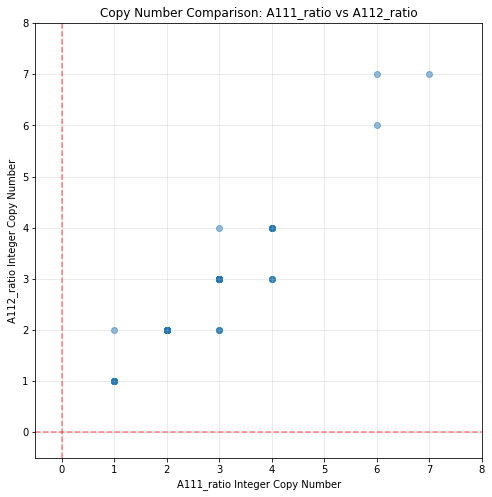

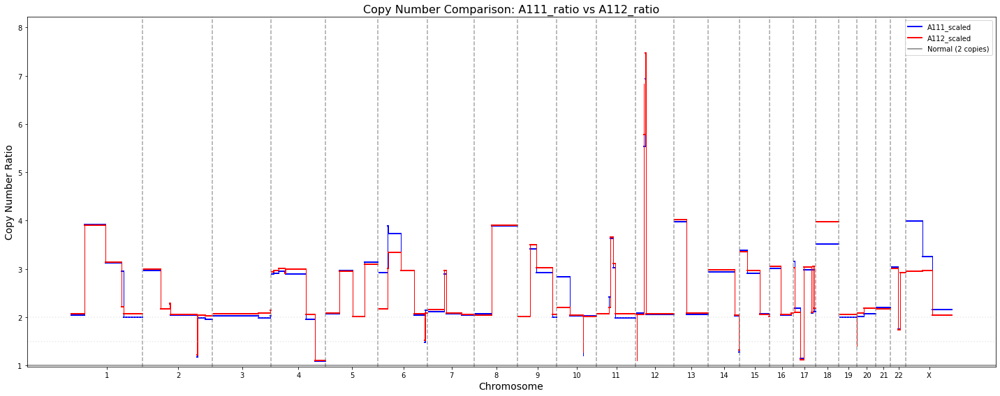

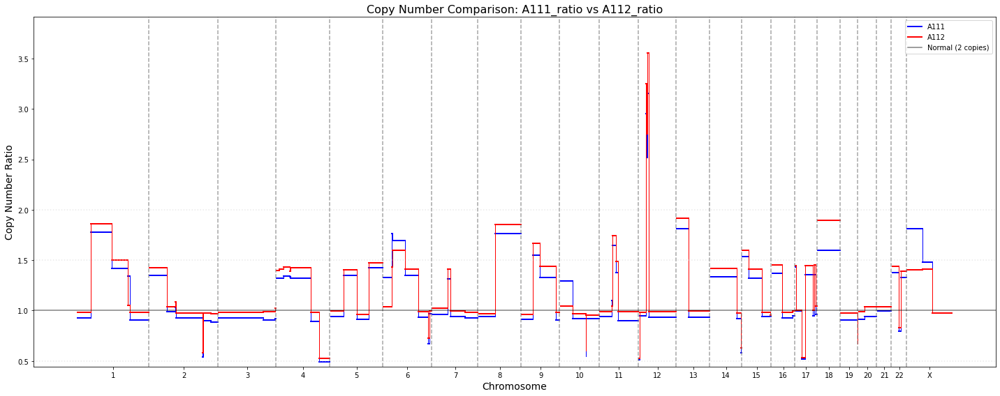

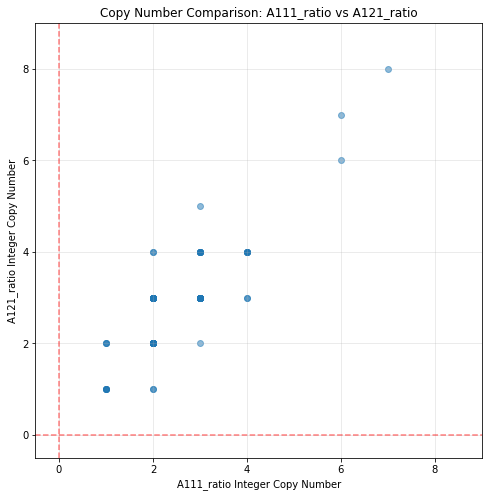

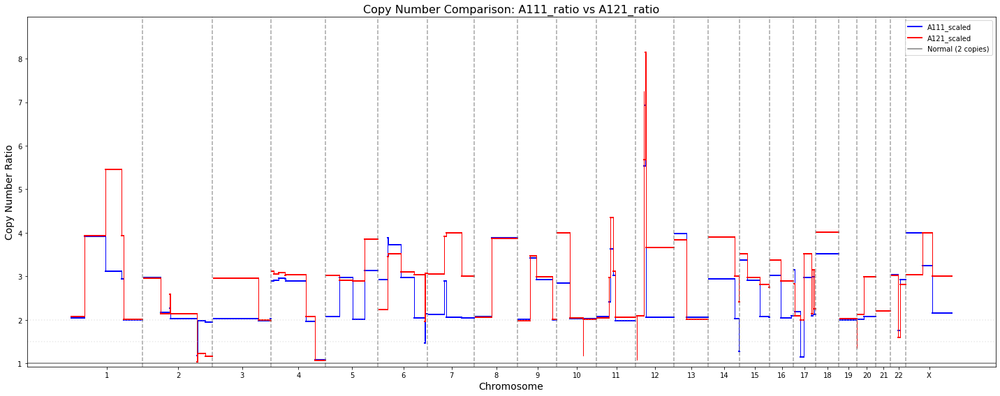

...

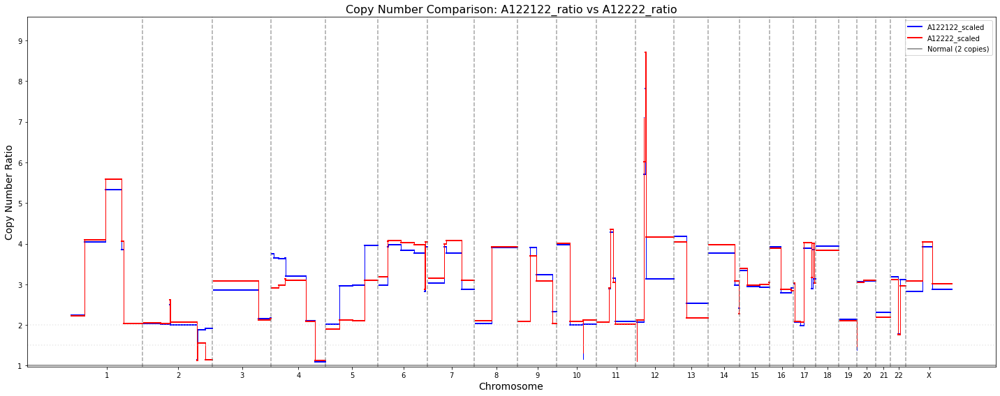

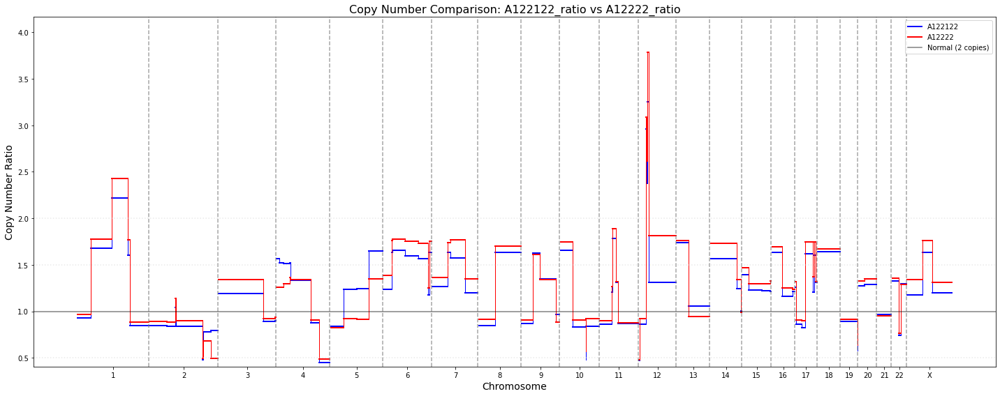

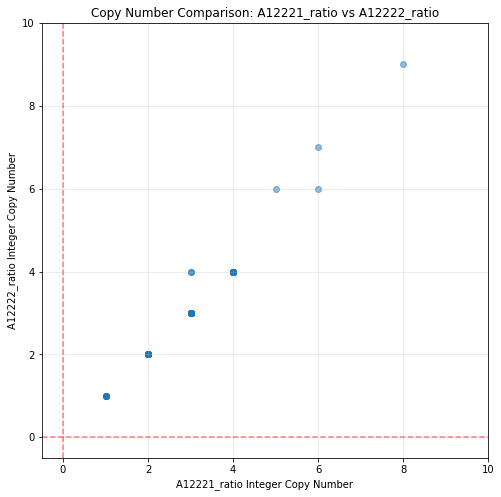

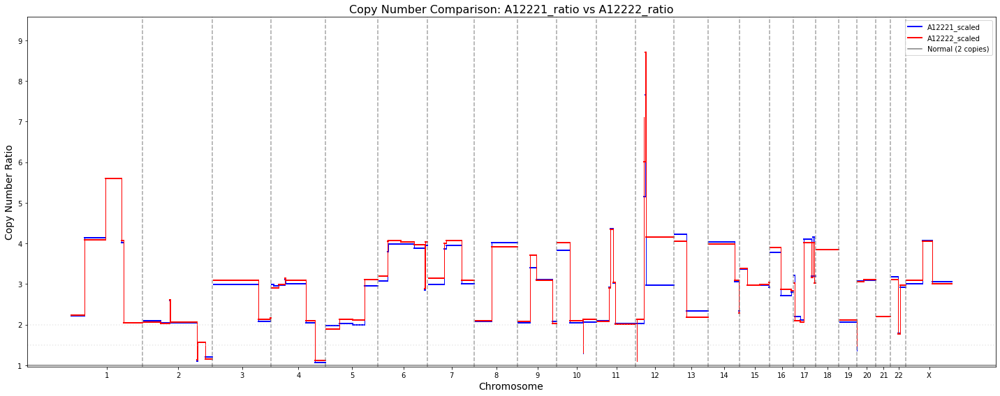

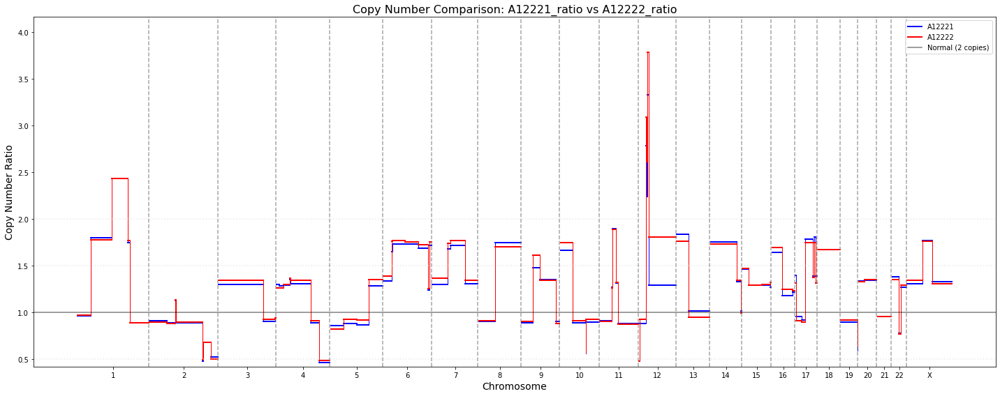

In [65]:
# Make pairwise plots for profile_dfs.keys() integer ratios
for i, pop_col1 in enumerate(profile_dfs.keys()):
    for j, pop_col2 in enumerate(profile_dfs.keys()):
        if i < j:
            df1 = profile_dfs[pop_col1]
            df2 = profile_dfs[pop_col2]
            plt.figure(figsize=(8, 8))
            plt.scatter(df1[f"{pop_col1}_integer"], df2[f"{pop_col2}_integer"], alpha=0.5)
            plt.xlabel(f"{pop_col1} Integer Copy Number")
            plt.ylabel(f"{pop_col2} Integer Copy Number")
            plt.title(f"Copy Number Comparison: {pop_col1} vs {pop_col2}")
            plt.xlim(-0.5, max(df1[f"{pop_col1}_integer"].max(), df2[f"{pop_col2}_integer"].max()) + 1)
            plt.ylim(-0.5, max(df1[f"{pop_col1}_integer"].max(), df2[f"{pop_col2}_integer"].max()) + 1)
            plt.grid(True, alpha=0.3)
            plt.axhline(y=0, color='red', linestyle='--', alpha=0.5)
            plt.axvline(x=0, color='red', linestyle='--', alpha=0.5)
            plt.show()
            # Plot two populations

            df = profile_dfs[pop_col1].copy()
            df[f"{pop_col2}_integer"] = profile_dfs[pop_col2][f"{pop_col2}_integer"]
            df[f"{pop_col2}_scaled"] = profile_dfs[pop_col2][f"{pop_col2}_scaled"]
            plot_copy_number_step_function(
                df, 
                [f"{pop_col1}_scaled", f"{pop_col2}_scaled"], 
                'Copy Number Comparison: ' + pop_col1 + ' vs ' + pop_col2
            )
            plot_copy_number_step_function(
                ratios_to_normal_1, 
                [pop_col1, pop_col2], 
                'Copy Number Comparison: ' + pop_col1 + ' vs ' + pop_col2
            )

        

In [66]:
def create_copy_number_matrix_fast(all_data, reassigned_populations, ratios_to_normal, ploidies, normal_pop_name):
    """
    Optimized version of copy number matrix creation using vectorized operations.
    
    Parameters:
    - all_data: DataFrame with segments as rows and cells as columns
    - reassigned_populations: Dictionary of populations with their cell lists
    - ratios_to_normal: DataFrame with ratio data
    - ploidies: Dictionary with optimal multipliers for each population
    - normal_pop_name: Name of the normal population
    
    Returns:
    - heatmap_df: DataFrame with copy numbers (segments × cells)
    - cell_pop_mapping: Dictionary mapping cells to their populations
    - pop_boundaries: List of tuples (pop_name, start_idx, end_idx)
    - segment_info: DataFrame with segment chromosome and position info
    """
    
    # Create cell to population mapping
    cell_pop_mapping = {}
    for pop_name, pop_data in reassigned_populations.items():
        for cell in pop_data["cells"]:
            cell_pop_mapping[cell] = pop_name
    
    # Order cells by population
    ordered_cells = []
    pop_boundaries = []
    current_pos = 0
    
    # Add normal population first
    normal_cells = reassigned_populations[normal_pop_name]["cells"]
    ordered_cells.extend(normal_cells)
    current_pos += len(normal_cells)
    pop_boundaries.append((normal_pop_name, 0, current_pos))
    
    # Add other populations
    for pop_name in sorted(reassigned_populations.keys()):
        if pop_name != normal_pop_name:
            pop_cells = reassigned_populations[pop_name]["cells"]
            ordered_cells.extend(pop_cells)
            start_pos = current_pos
            current_pos += len(pop_cells)
            pop_boundaries.append((pop_name, start_pos, current_pos))
    
    # Order segments by chromosome and position
    segment_order = ratios_to_normal[['chrom', 'start', 'end']].copy()
    chrom_order = ['chr' + str(i) for i in range(1, 23)] + ['chrX']
    segment_order['chrom_num'] = segment_order['chrom'].apply(
        lambda x: chrom_order.index(x) if x in chrom_order else 999
    )
    segment_order = segment_order.sort_values(['chrom_num', 'start']).reset_index(drop=True)
    ordered_segment_indices = segment_order.index
    
    # Get ordered data (this is the key optimization)
    ordered_data = all_data.iloc[ordered_segment_indices][ordered_cells]
    
    print(f"Processing {len(ordered_segment_indices)} segments using vectorized operations...")
    
    # Step 1: Compute normal_factor (segment average for normal cells)
    normal_cells_data = ordered_data.loc[:, ordered_data.columns.isin(normal_cells)]
    normal_factor = normal_cells_data.mean(axis=1).values  # Average across normal cells for each segment
    normal_factor = np.where(normal_factor > 0, normal_factor, 1)  # Avoid division by zero
    
    print("Normal factor computed")
    
    # Step 2: Normalize all cells by normal_factor
    normalized_data = ordered_data.div(normal_factor, axis=0)
    
    print("Data normalized by normal factor")
    
    # Step 3: For each cell, normalize by mean over all segments in that cell
    cell_means = normalized_data.mean(axis=0)  # Mean for each cell across all segments
    cell_means = np.where(cell_means > 0, cell_means, 1)  # Avoid division by zero
    
    # Normalize each cell by its own mean
    doubly_normalized_data = normalized_data.div(cell_means, axis=1)
    
    print("Data normalized by cell means")
    
    # Step 4: Apply ploidy multipliers
    heatmap_data = np.zeros_like(doubly_normalized_data.values, dtype=float)
    
    for i, cell in enumerate(ordered_cells):
        cell_pop = cell_pop_mapping[cell]
        
        # Get appropriate multiplier
        if cell_pop == normal_pop_name:
            multiplier = 2.0  # Normal cells get multiplier of 2
        else:
            pop_ratio_col = f"{cell_pop}_ratio"
            multiplier = ploidies.get(pop_ratio_col, 2.0)  # Use ploidy multiplier or default to 2
        
        # Apply multiplier to this cell's data
        heatmap_data[:, i] = doubly_normalized_data.iloc[:, i].values * multiplier
    
    print("Ploidy multipliers applied")
    
    # Create segment labels
    segment_labels = [
        f"{segment_order.loc[seg_idx, 'chrom']}:{segment_order.loc[seg_idx, 'start']}-{segment_order.loc[seg_idx, 'end']}"
        for seg_idx in ordered_segment_indices
    ]
    
    # Create heatmap DataFrame
    heatmap_df = pd.DataFrame(heatmap_data, columns=ordered_cells, index=segment_labels)
    
    # Create segment info DataFrame
    segment_info = segment_order[['chrom', 'start', 'end', 'chrom_num']].copy()
    segment_info.index = segment_labels
    
    print("Copy number matrix created successfully!")
    
    return heatmap_df, cell_pop_mapping, pop_boundaries, segment_info

In [73]:
def plot_copy_number_heatmap(heatmap_df, pop_boundaries, segment_info, title="Copy Number Heatmap"):
    """
    Plot the copy number heatmap with segments displayed proportional to their genomic size.
    
    Parameters:
    - heatmap_df: DataFrame with copy numbers (segments × cells)
    - pop_boundaries: List of tuples (pop_name, start_idx, end_idx)
    - segment_info: DataFrame with segment chromosome info
    - title: Plot title
    """
    
    # Calculate segment lengths
    segment_lengths = segment_info['end'] - segment_info['start']
    
    # Normalize segment lengths to determine how many rows each segment gets
    # Scale so that smallest segment gets 1 row, largest gets proportional amount
    min_length = segment_lengths.min()
    max_rows_per_segment = 10  # Maximum rows any single segment can occupy
    
    # Calculate rows per segment based on length (minimum 1 row)
    rows_per_segment = np.maximum(1, np.round(segment_lengths / min_length).astype(int))
    # Cap at maximum to prevent huge chromosomes from dominating
    rows_per_segment = np.minimum(rows_per_segment, max_rows_per_segment)
    
    # Create expanded heatmap data
    expanded_data = []
    expanded_chroms = []
    chrom_positions = {}  # Track position of each chromosome
    current_row = 0
    
    print(f"Expanding heatmap from {len(heatmap_df)} segments to {rows_per_segment.sum()} rows...")
    
    for i, (seg_label, row_data) in enumerate(heatmap_df.iterrows()):
        chrom = segment_info.iloc[i]['chrom']
        repeats = rows_per_segment.iloc[i]
        
        # Track chromosome boundaries
        if chrom not in chrom_positions:
            chrom_positions[chrom] = {'start': current_row, 'rows': 0}
        
        # Add this segment's data multiple times based on its size
        for _ in range(repeats):
            expanded_data.append(row_data.values)
            expanded_chroms.append(chrom)
            current_row += 1
            chrom_positions[chrom]['rows'] += 1
    
    expanded_data = np.array(expanded_data)
    
    # Calculate chromosome centers for labeling
    chrom_centers = []
    chrom_labels = []
    chrom_order = ['chr' + str(i) for i in range(1, 23)] + ['chrX']
    
    for chrom in chrom_order:
        if chrom in chrom_positions:
            start = chrom_positions[chrom]['start']
            rows = chrom_positions[chrom]['rows']
            center = start + rows / 2
            chrom_centers.append(center)
            chrom_labels.append(chrom)
    
    # Create the plot
    fig, ax = plt.subplots(figsize=(20, 15))
    
    # Create custom colormap: blue (deletions) -> white (CN=2) -> red (amplifications)
    from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
    
    colors_list = [
        (0.0, 'darkblue'),     # CN = 0
        (0.25, 'blue'),        # CN = 1
        (0.5, 'white'),        # CN = 2 (normal)
        (0.75, 'red'),         # CN = 3-4
        (1.0, 'darkred')       # CN = 5+
    ]
    
    cmap = LinearSegmentedColormap.from_list('copy_number', colors_list, N=256)
    norm = TwoSlopeNorm(vmin=0, vcenter=2, vmax=6)
    
    # Plot heatmap
    im = ax.imshow(expanded_data, aspect='auto', cmap=cmap, norm=norm)
    
    # Add population boundaries (vertical lines only - no text labels here)
    for pop_name, start, end in pop_boundaries:
        ax.axvline(x=start-0.5, color='black', linewidth=2)
        ax.axvline(x=end-0.5, color='black', linewidth=2)
    
    # Add chromosome boundaries (horizontal lines)
    current_pos = 0
    for chrom in chrom_order:
        if chrom in chrom_positions:
            current_pos += chrom_positions[chrom]['rows']
            if chrom != chrom_order[-1]:  # Don't add line after last chromosome
                ax.axhline(y=current_pos-0.5, color='gray', linewidth=1, alpha=0.7)
    
    # Set labels and title
    ax.set_title(title, fontsize=16, pad=20)
    ax.set_xlabel('Cells (ordered by population)', fontsize=12)
    
    # Set population tick labels at bottom (this is the only place we add labels)
    cell_tick_positions = [boundary[1] + (boundary[2] - boundary[1]) / 2 for boundary in pop_boundaries]
    cell_tick_labels = [boundary[0] for boundary in pop_boundaries]
    ax.set_xticks(cell_tick_positions)
    ax.set_xticklabels(cell_tick_labels, rotation=45)
    
    # Set chromosome labels on y-axis (one label per chromosome at center)
    ax.set_yticks(chrom_centers)
    ax.set_yticklabels(chrom_labels)
    
    # Add colorbar with simple numeric labels
    cbar = plt.colorbar(im, ax=ax, shrink=0.8)
    cbar.set_label('Copy Number', fontsize=12)
    
    # Set colorbar ticks to just numbers
    cbar_ticks = [0, 1, 2, 3, 4, 5, 6]
    cbar.set_ticks(cbar_ticks)
    cbar.set_ticklabels(['0', '1', '2', '3', '4', '5', '6+'])
    
    # Print chromosome size information
    print("\nChromosome representation in heatmap:")
    for chrom in chrom_order:
        if chrom in chrom_positions:
            rows = chrom_positions[chrom]['rows']
            # Calculate total genomic length for this chromosome
            chrom_segs = segment_info[segment_info['chrom'] == chrom]
            total_length = (chrom_segs['end'] - chrom_segs['start']).sum()
            print(f"{chrom}: {rows} rows, {total_length:,} bp total")
    
    plt.tight_layout()
    plt.show()

Processing 89 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Heatmap matrix dimensions: 89 segments × 2533 cells
Expanding heatmap from 89 segments to 794 rows...

Chromosome representation in heatmap:
chr1: 50 rows, 246,159,932 bp total
chr2: 60 rows, 235,824,599 bp total
chr3: 24 rows, 196,141,480 bp total
chr4: 62 rows, 183,819,298 bp total
chr5: 40 rows, 178,463,482 bp total
chr6: 64 rows, 166,930,960 bp total
chr7: 40 rows, 156,878,815 bp total
chr8: 20 rows, 145,153,934 bp total
chr9: 40 rows, 130,597,528 bp total
chr10: 31 rows, 132,750,269 bp total
chr11: 47 rows, 132,171,512 bp total
chr12: 36 rows, 127,192,322 bp total
chr13: 20 rows, 113,902,193 bp total
chr14: 22 rows, 105,604,444 bp total
chr15: 34 rows, 100,011,182 bp total
chr16: 30 rows, 77,331,877 bp total
chr17: 62 rows, 73,991,953 bp total
chr18: 10 rows, 77,454,799 bp tot

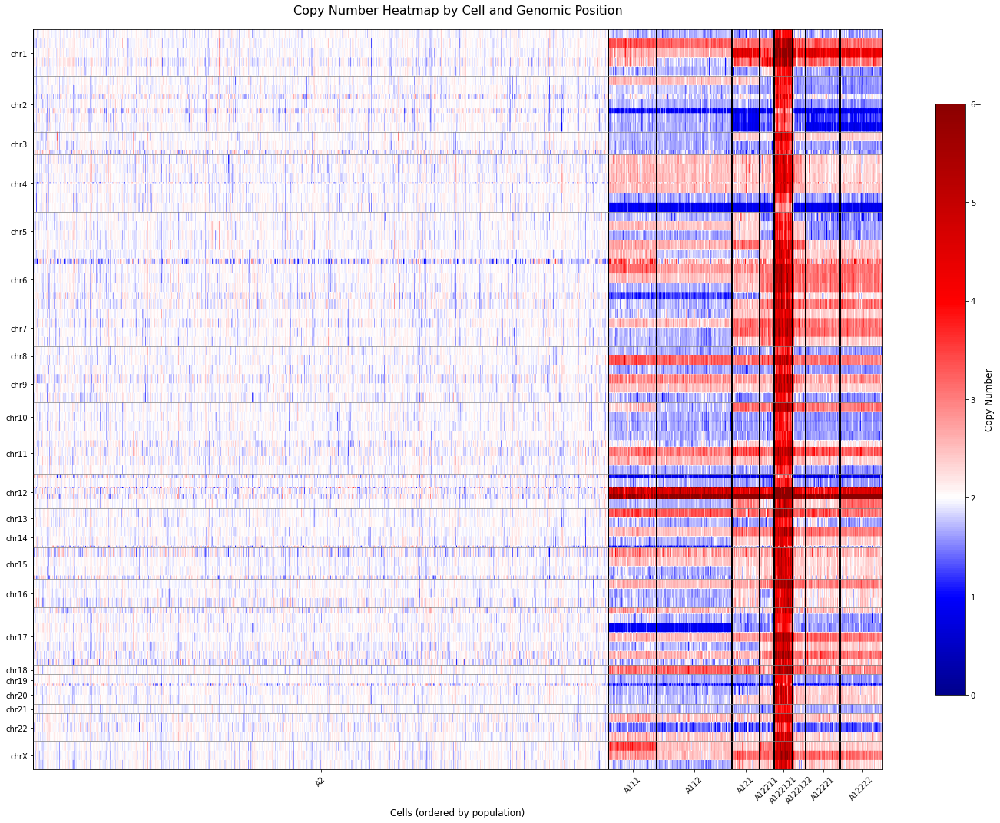

In [74]:
# Use the optimized function with consistent normalization
heatmap_df, cell_mapping, boundaries, segment_info = create_copy_number_matrix_fast(
    all_data, 
    reassigned_populations, 
    ratios_to_normal_1, 
    ploidies, 
    normal_pop_name_1
)

print(f"Heatmap matrix dimensions: {heatmap_df.shape[0]} segments × {heatmap_df.shape[1]} cells")

# Then plot it with simplified parameters
plot_copy_number_heatmap(
    heatmap_df, 
    boundaries, 
    segment_info,
    title="Copy Number Heatmap by Cell and Genomic Position"
)

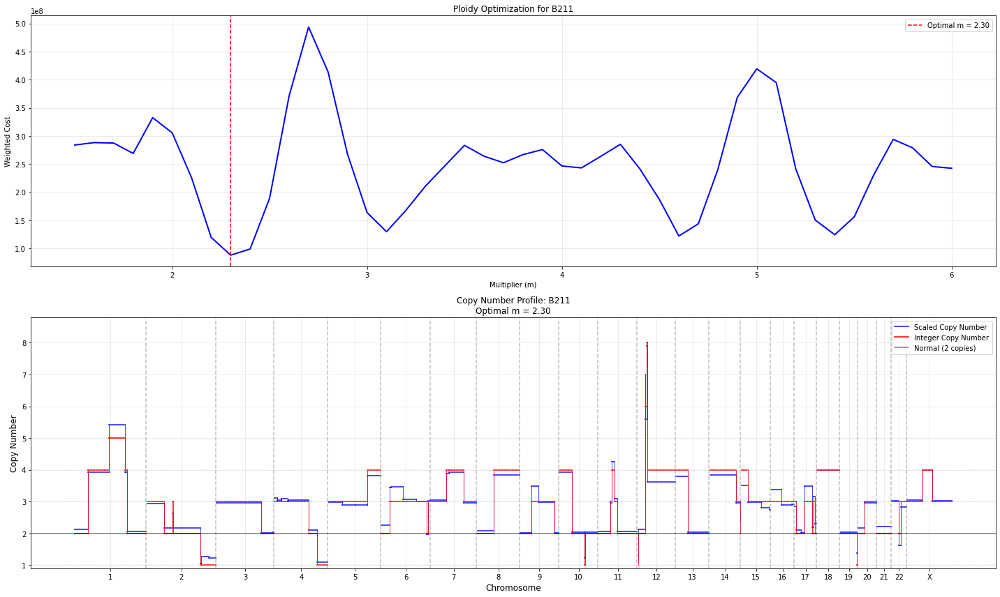


Optimal Results for B211:
Optimal multiplier (m): 2.300
Minimum cost: 8.82e+07
Average copy number: 2.91



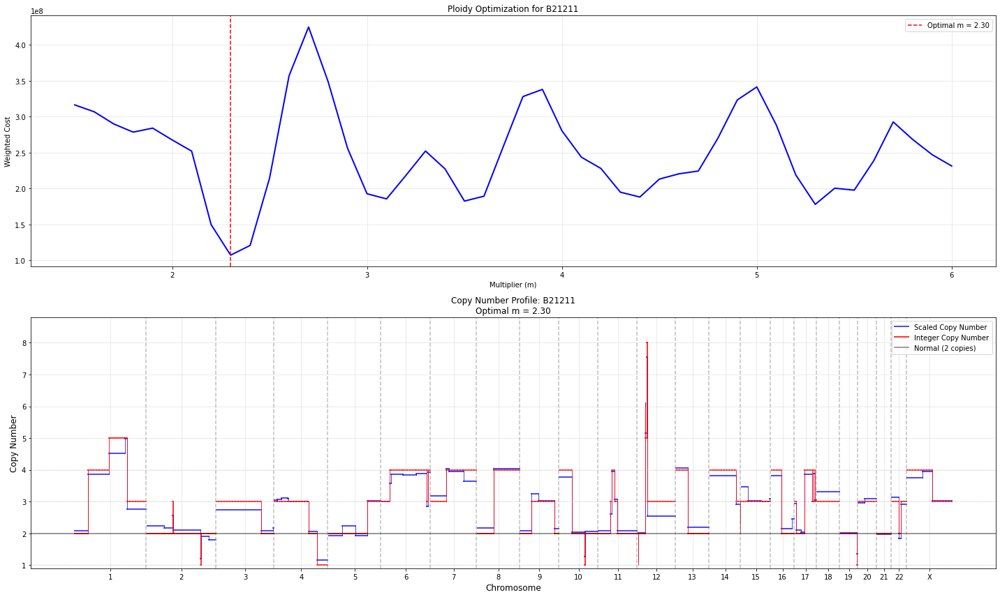


Optimal Results for B21211:
Optimal multiplier (m): 2.300
Minimum cost: 1.07e+08
Average copy number: 2.91



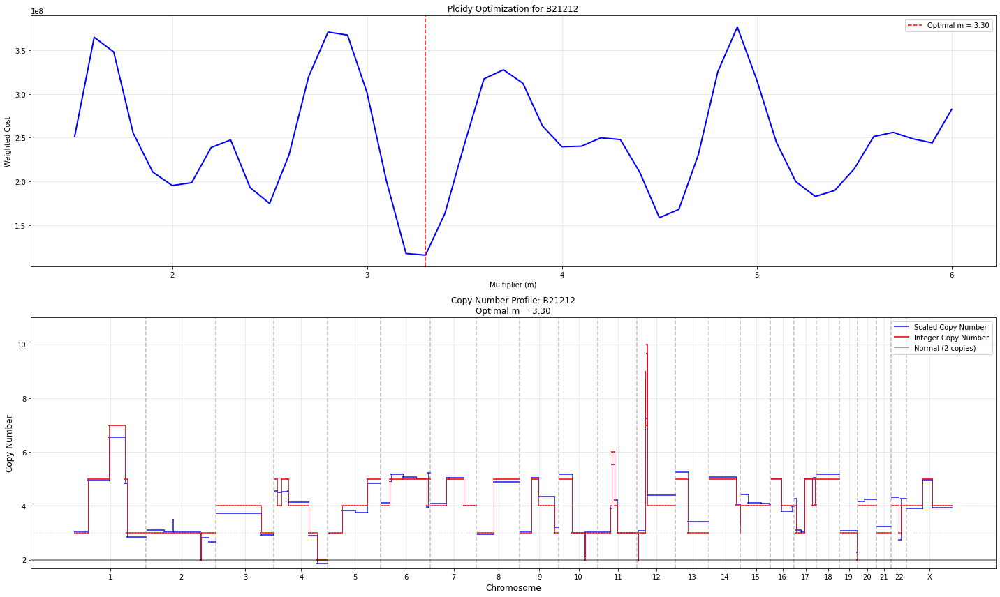


Optimal Results for B21212:
Optimal multiplier (m): 3.300
Minimum cost: 1.16e+08
Average copy number: 3.98



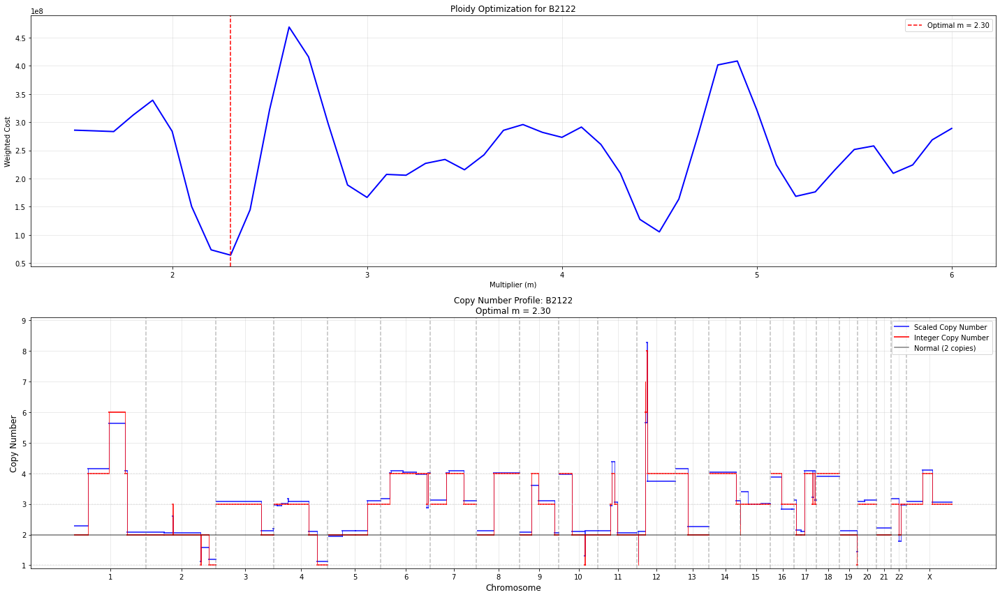


Optimal Results for B2122:
Optimal multiplier (m): 2.300
Minimum cost: 6.42e+07
Average copy number: 2.94



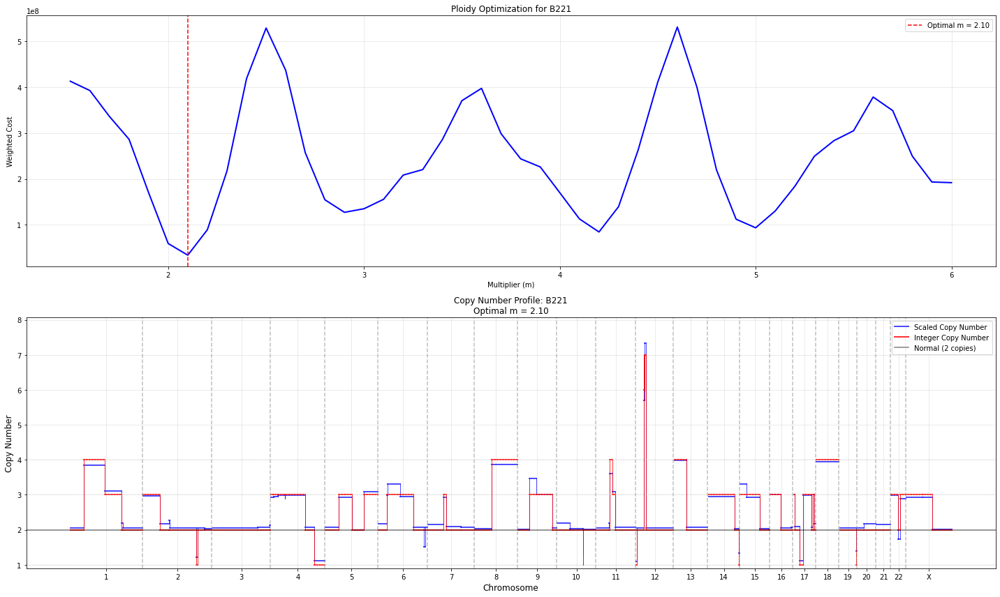


Optimal Results for B221:
Optimal multiplier (m): 2.100
Minimum cost: 3.40e+07
Average copy number: 2.48



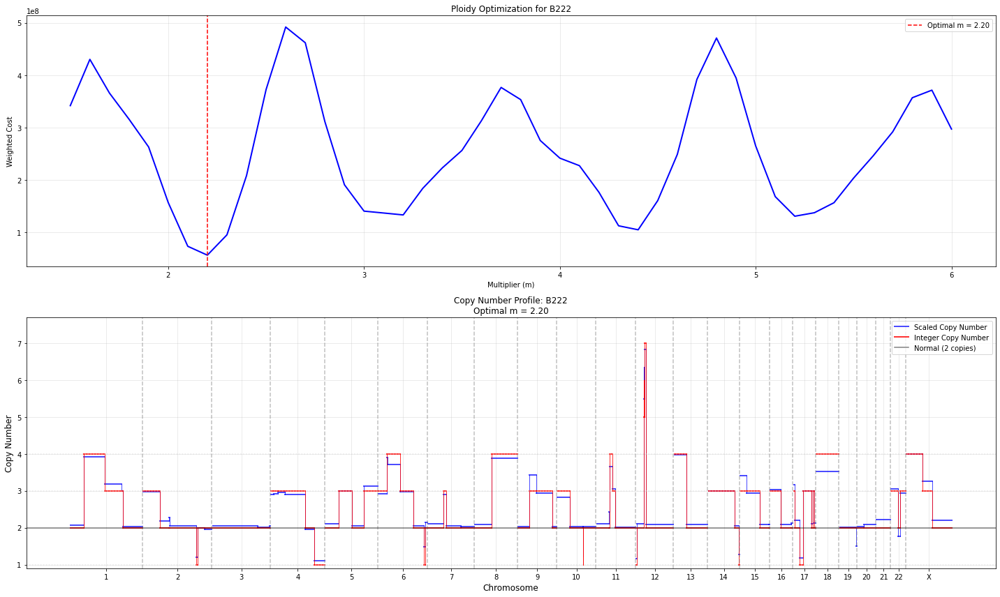


Optimal Results for B222:
Optimal multiplier (m): 2.200
Minimum cost: 5.68e+07
Average copy number: 2.54


In [75]:
# For population B - compute optimal ploidy for each non-normal population
profile_dfs_2 = {}
ploidies_2 = {}
pop_names_2 = ratios_to_normal_2.columns[4:]

for pop_col in pop_names_2:
    if pop_col != f"{normal_pop_name_2}_ratio":  # Skip normal population
        print(f"\n{'='*50}")
        optimal_m, min_cost, profile_df, costs = compute_optimal_ploidy_and_profile(
            ratios_to_normal_2, pop_col, m_range=[1.5, 6], step_size=0.1, plot=True
        )
        profile_dfs_2[pop_col] = profile_df
        ploidies_2[pop_col] = optimal_m

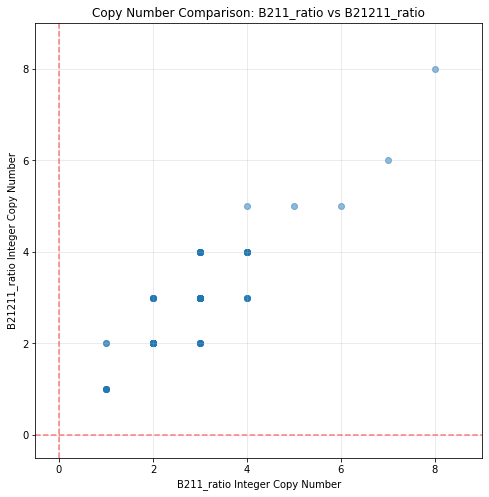

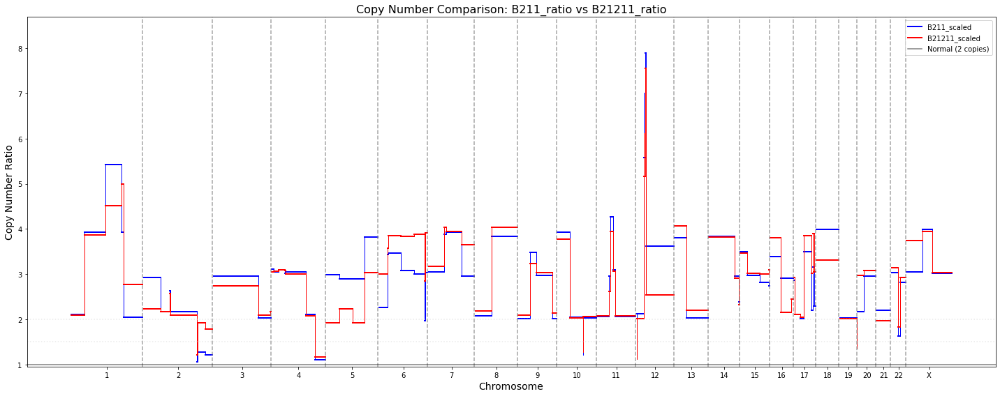

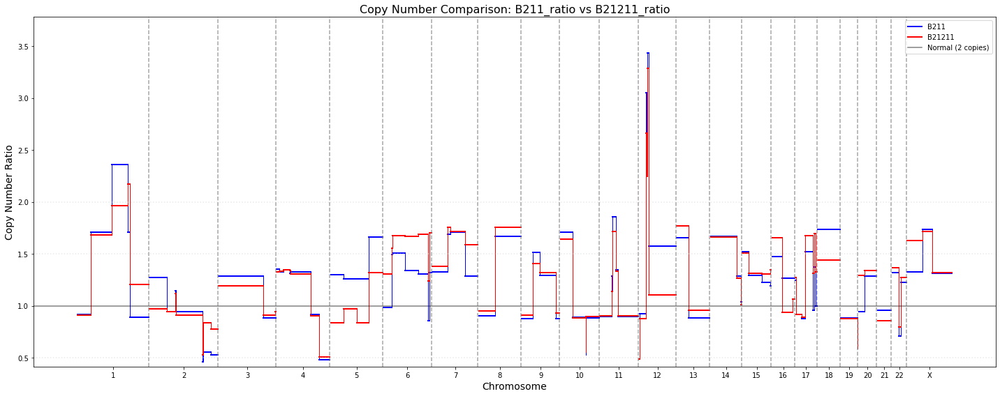

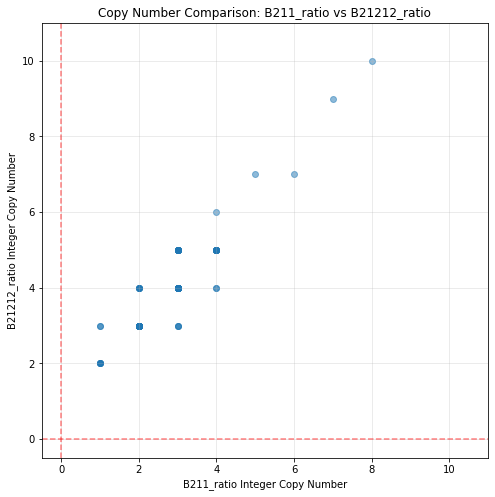

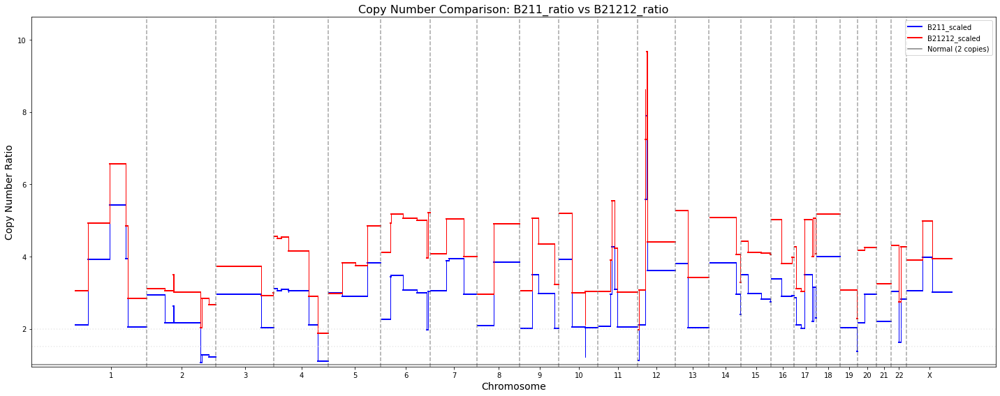

...

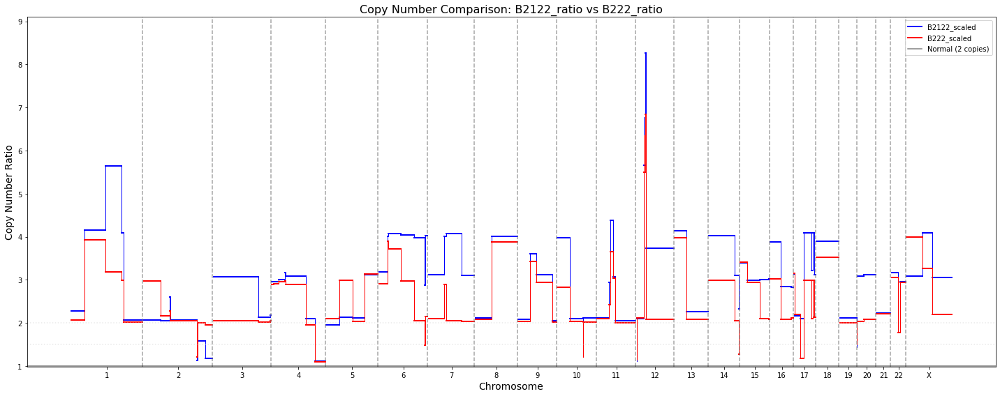

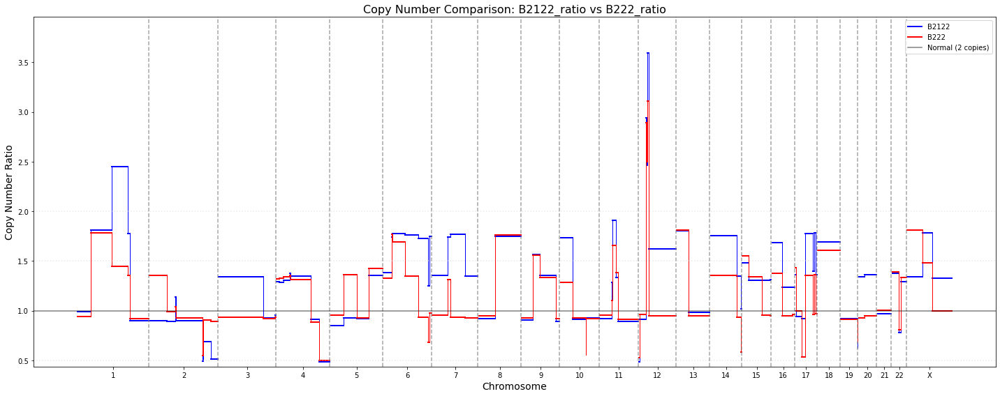

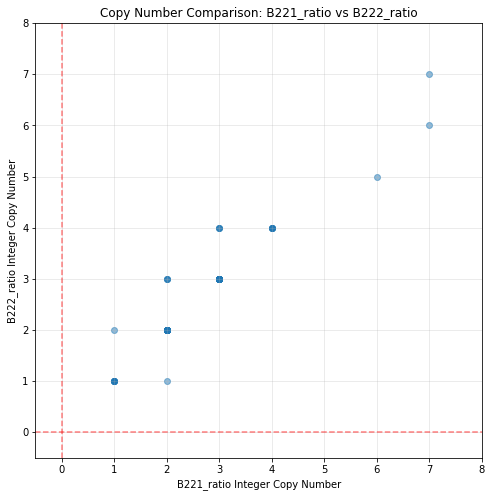

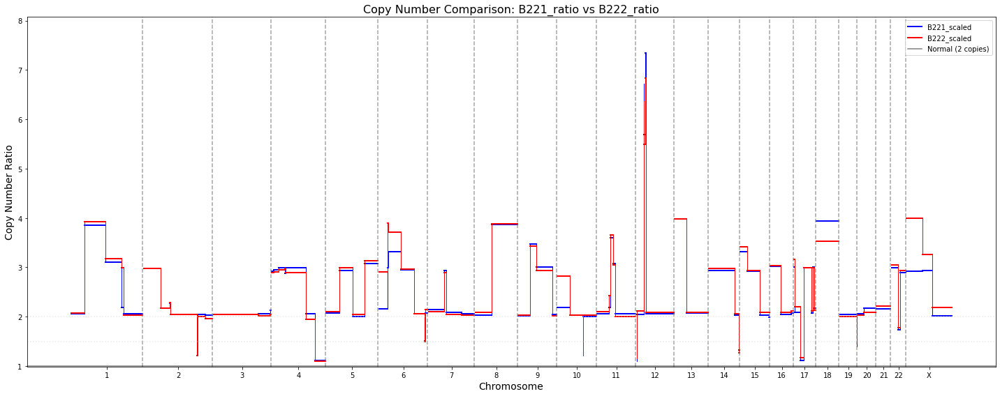

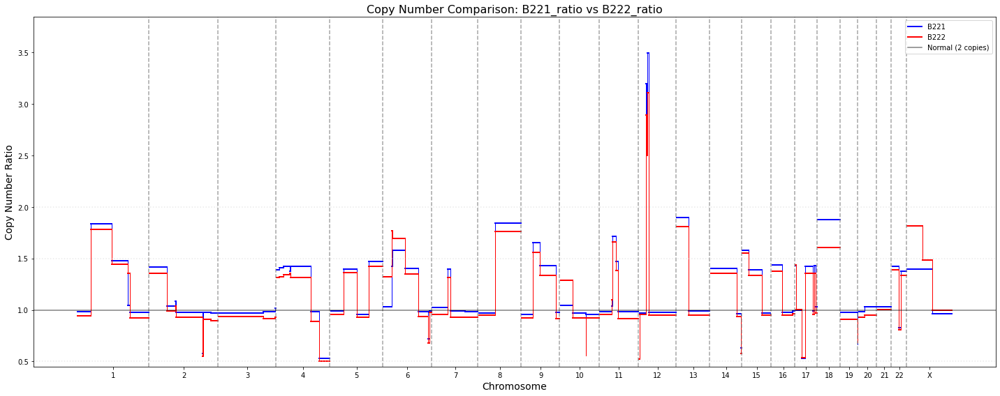

In [76]:
# Make pairwise plots for population B integer ratios
for i, pop_col1 in enumerate(profile_dfs_2.keys()):
    for j, pop_col2 in enumerate(profile_dfs_2.keys()):
        if i < j:
            df1 = profile_dfs_2[pop_col1]
            df2 = profile_dfs_2[pop_col2]
            plt.figure(figsize=(8, 8))
            plt.scatter(df1[f"{pop_col1}_integer"], df2[f"{pop_col2}_integer"], alpha=0.5)
            plt.xlabel(f"{pop_col1} Integer Copy Number")
            plt.ylabel(f"{pop_col2} Integer Copy Number")
            plt.title(f"Copy Number Comparison: {pop_col1} vs {pop_col2}")
            plt.xlim(-0.5, max(df1[f"{pop_col1}_integer"].max(), df2[f"{pop_col2}_integer"].max()) + 1)
            plt.ylim(-0.5, max(df1[f"{pop_col1}_integer"].max(), df2[f"{pop_col2}_integer"].max()) + 1)
            plt.grid(True, alpha=0.3)
            plt.axhline(y=0, color='red', linestyle='--', alpha=0.5)
            plt.axvline(x=0, color='red', linestyle='--', alpha=0.5)
            plt.show()
            
            # Plot two populations with scaled values
            df = profile_dfs_2[pop_col1].copy()
            df[f"{pop_col2}_integer"] = profile_dfs_2[pop_col2][f"{pop_col2}_integer"]
            df[f"{pop_col2}_scaled"] = profile_dfs_2[pop_col2][f"{pop_col2}_scaled"]
            plot_copy_number_step_function(
                df, 
                [f"{pop_col1}_scaled", f"{pop_col2}_scaled"], 
                'Copy Number Comparison: ' + pop_col1 + ' vs ' + pop_col2
            )
            
            # Plot with original ratios
            plot_copy_number_step_function(
                ratios_to_normal_2, 
                [pop_col1, pop_col2], 
                'Copy Number Comparison: ' + pop_col1 + ' vs ' + pop_col2
            )

Processing 89 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Heatmap matrix dimensions for population B: 89 segments × 2533 cells
Expanding heatmap from 89 segments to 794 rows...

Chromosome representation in heatmap:
chr1: 50 rows, 246,159,932 bp total
chr2: 60 rows, 235,824,599 bp total
chr3: 24 rows, 196,141,480 bp total
chr4: 62 rows, 183,819,298 bp total
chr5: 40 rows, 178,463,482 bp total
chr6: 64 rows, 166,930,960 bp total
chr7: 40 rows, 156,878,815 bp total
chr8: 20 rows, 145,153,934 bp total
chr9: 40 rows, 130,597,528 bp total
chr10: 31 rows, 132,750,269 bp total
chr11: 47 rows, 132,171,512 bp total
chr12: 36 rows, 127,192,322 bp total
chr13: 20 rows, 113,902,193 bp total
chr14: 22 rows, 105,604,444 bp total
chr15: 34 rows, 100,011,182 bp total
chr16: 30 rows, 77,331,877 bp total
chr17: 62 rows, 73,991,953 bp total
chr18: 10 rows, 

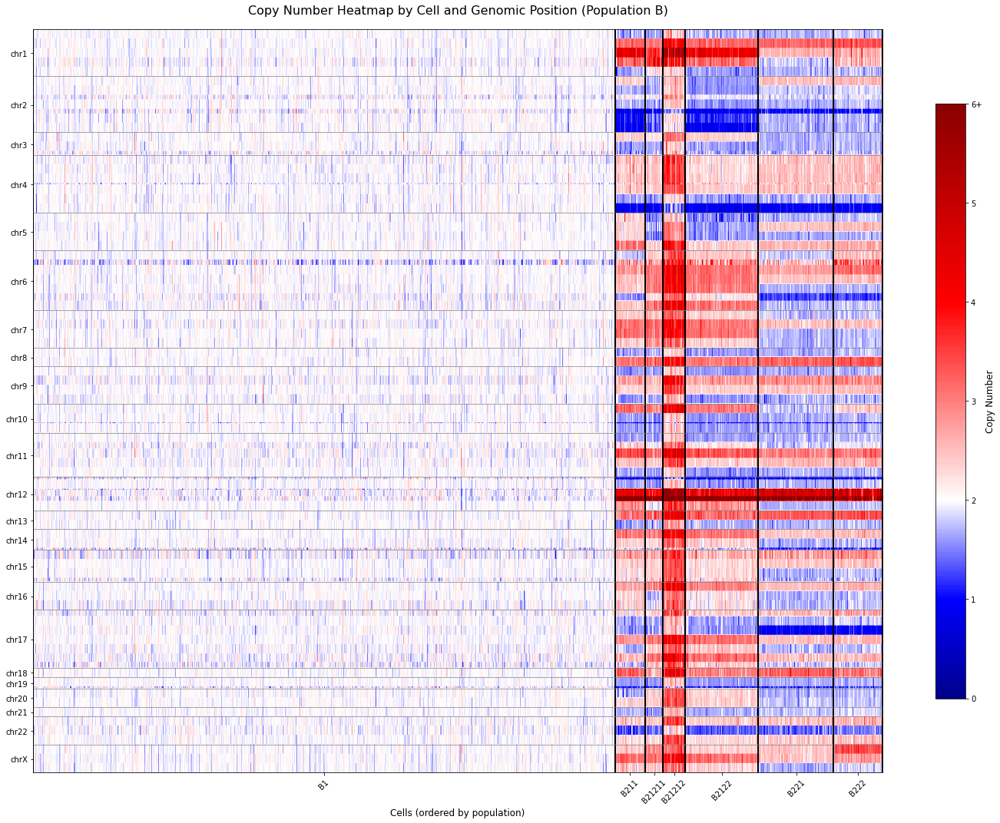

In [77]:
# Create copy number matrix for population B
heatmap_df_2, cell_mapping_2, boundaries_2, segment_info_2 = create_copy_number_matrix_fast(
    all_data, 
    reassigned_populations_2, 
    ratios_to_normal_2, 
    ploidies_2, 
    normal_pop_name_2
)

print(f"Heatmap matrix dimensions for population B: {heatmap_df_2.shape[0]} segments × {heatmap_df_2.shape[1]} cells")

# Plot the heatmap for population B
plot_copy_number_heatmap(
    heatmap_df_2, 
    boundaries_2, 
    segment_info_2,
    title="Copy Number Heatmap by Cell and Genomic Position (Population B)"
)

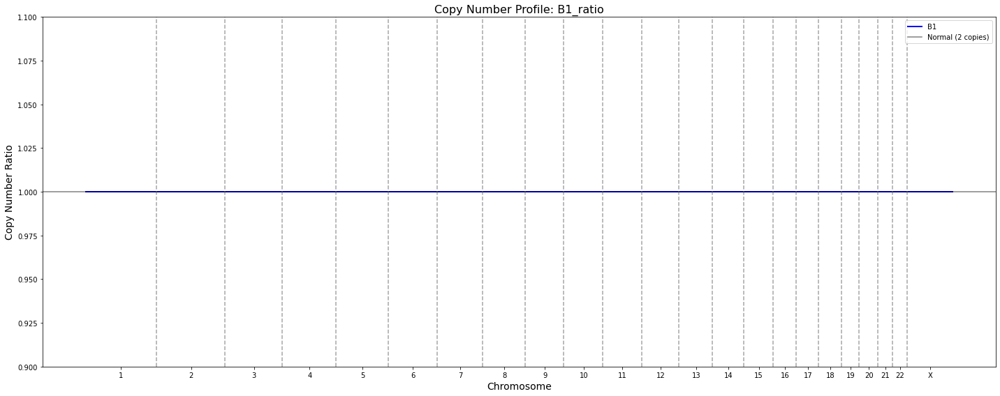

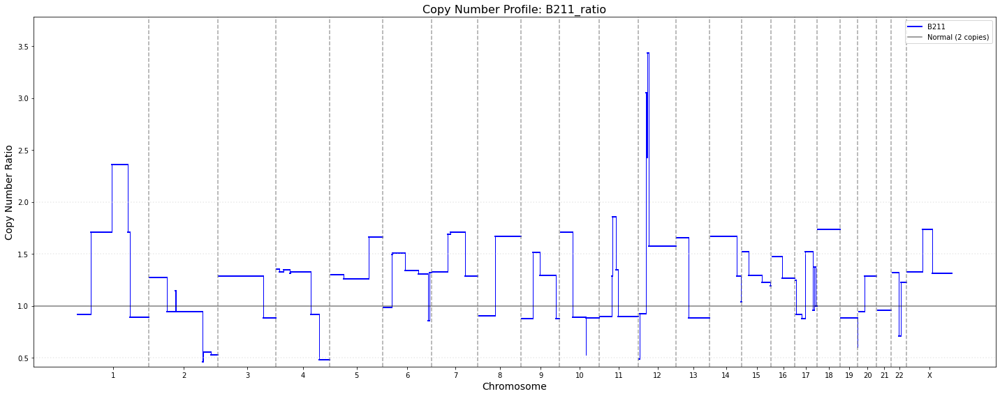

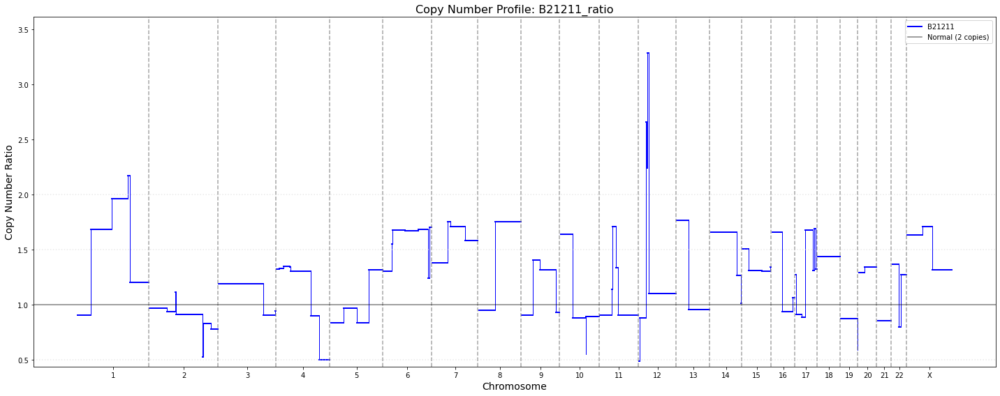

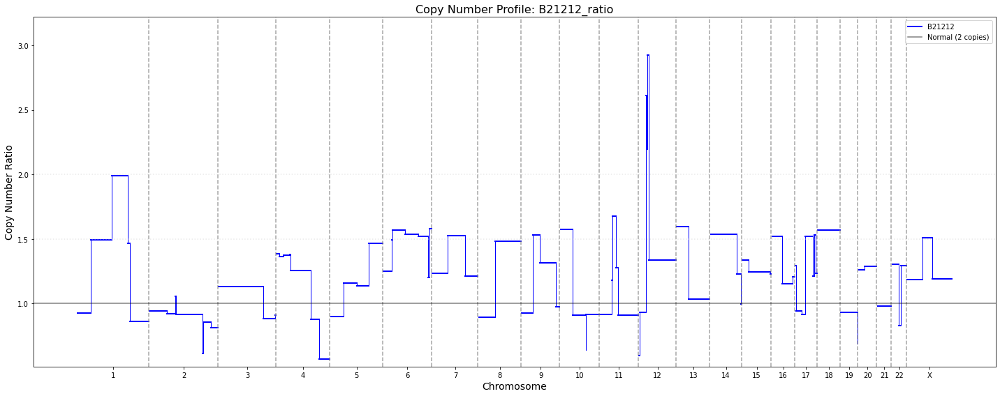

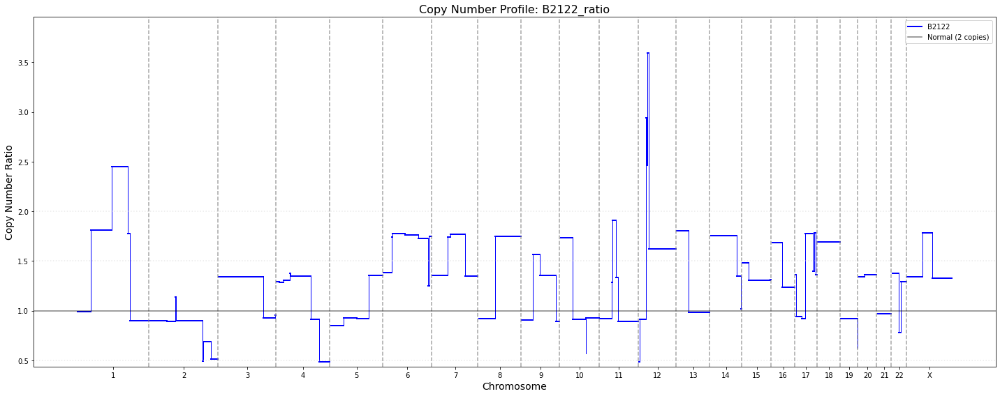

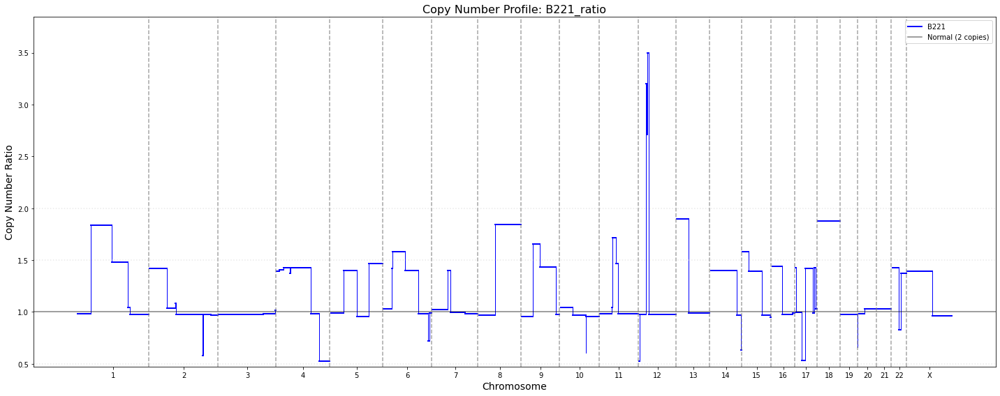

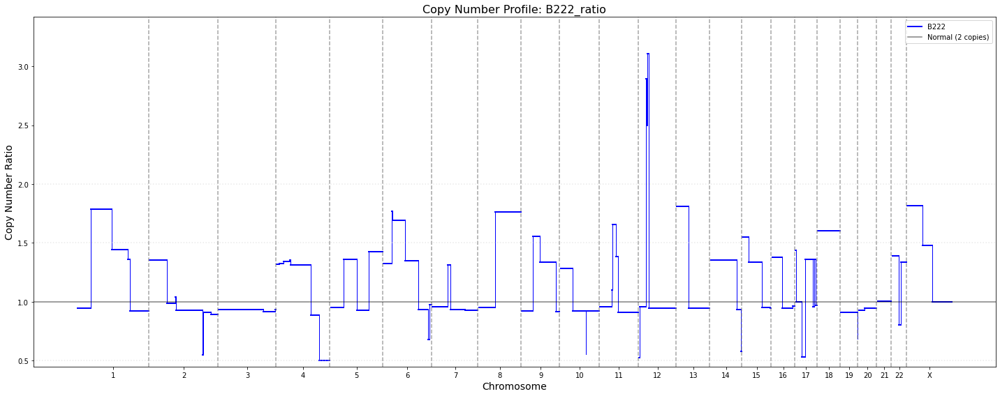

In [78]:
# Plot individual population profiles for population B
for pop in pop_names_2:
    plot_copy_number_step_function(
        ratios_to_normal_2, 
        [pop], 
        'Copy Number Profile: '+ pop
    )

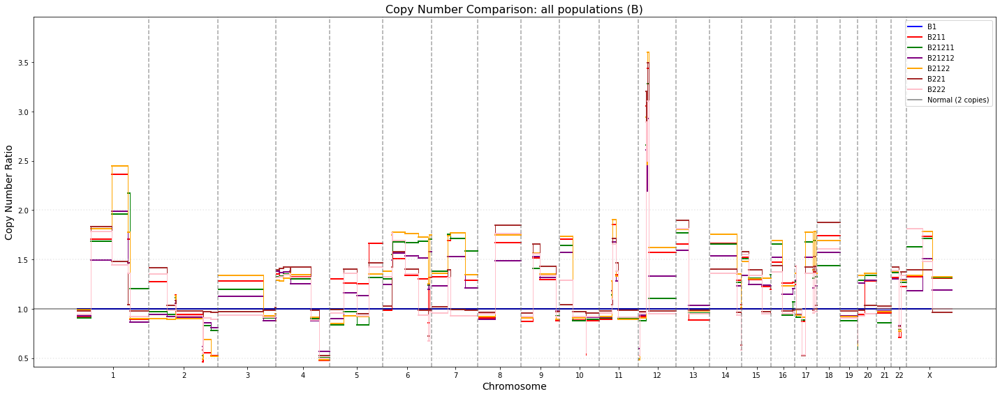

In [79]:
# Plot all populations together for population B
plot_copy_number_step_function(
    ratios_to_normal_2, 
    pop_names_2, 
    'Copy Number Comparison: all populations (B)'
)